In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import math
import autoroot

m_key_dict = {
        'LSTM': 'module.layers.LSTM.hidden_size',
        'S4': 'module.layers.Layer2.d_model',
        'TCN': 'module.layers.Layer2.channel',
        'Trans_hid_dim': 'module.layers.Layer1.hid_dim',
        'Trans_nhead': 'module.layers.Layer1.nhead'
    }

In [9]:
def plot_basic(project, model, legend1=True, e=1e-6, conditions=None, path='./notebooks/Dataset/step1/data2'):

    

    m_key = m_key_dict[model]

    df = pd.read_pickle(f"{path}/{project}_data_clean.pkl")
    df['m'] = df[m_key]

    if conditions:
        for op in conditions:
            df = df.query(op)

    df['steps_to_reach_e'] = df['loss_history'].apply(
        lambda losses: next((i for i, val in enumerate(losses) if float(val) < float(e)), None))
    
    plt.figure(figsize=(10, 6))
    
    palette = sns.color_palette("tab10", n_colors=len(df['data.rho_param.alpha'].unique()))

    df_min = df.groupby(['m', 'data.rho_param.alpha'], as_index=False)['train/rLoss1_epoch.min'].min()

    sns.lineplot(
        data=df_min,
        x='m',
        y='train/rLoss1_epoch.min',
        hue='data.rho_param.alpha',
        marker='o',
        palette=palette,
        legend=legend1
    )



    plt.yscale('log')
    plt.title('Loss vs m for Different rho_param (Log Scale)')
    plt.xlabel('m')
    plt.ylabel('train/rLoss1_epoch.min (log scale)')

    if legend1:
        plt.legend(title='rho_param')
        
    plt.grid(True, which="both", ls="--")
    plt.tight_layout()
    plt.show()

    # Create the lineplot with x as rho_param, y as loss, each line for a different m
    plt.figure(figsize=(10, 6))
    palette = sns.color_palette("tab10", n_colors=len(df['m'].unique()))

    sns.lineplot(
        data=df_min,
        x='data.rho_param.alpha',
        y='train/rLoss1_epoch.min',
        hue='m',
        marker='o',
        palette=palette
    )

    plt.yscale('log')
    plt.title('Loss vs rho_param for Different m (Log Scale)')
    plt.xlabel('rho_param')
    plt.ylabel('train/rLoss1_epoch.min (log scale)')
    plt.legend(title='m')
    plt.grid(True, which="both", ls="--")
    plt.tight_layout()
    plt.show()


    # Drop NAs
    plot_df = df.dropna(subset=['steps_to_reach_e'])

    # Group by alpha and m, and get the min steps_to_reach_e
    plot_df_min = plot_df.groupby(['data.rho_param.alpha', 'm'], as_index=False)['steps_to_reach_e'].min()


    # Plot with actual DataFrame
    plt.figure(figsize=(10, 6))
    palette = sns.color_palette("tab10", n_colors=plot_df['m'].nunique())


    sns.lineplot(
        data=plot_df_min,
        x='data.rho_param.alpha',
        y='steps_to_reach_e',
        hue='m',
        marker='o',
        palette=palette
    )

    plt.title('Min Steps to Reach Threshold vs Alpha (Grouped by m)')
    plt.xlabel('alpha (rho_param)')
    plt.ylabel(f'Steps to reach loss e')
    plt.legend(title='m')
    plt.grid(True)
    plt.tight_layout()
    plt.show()

# LSTM

## LSTM Exp

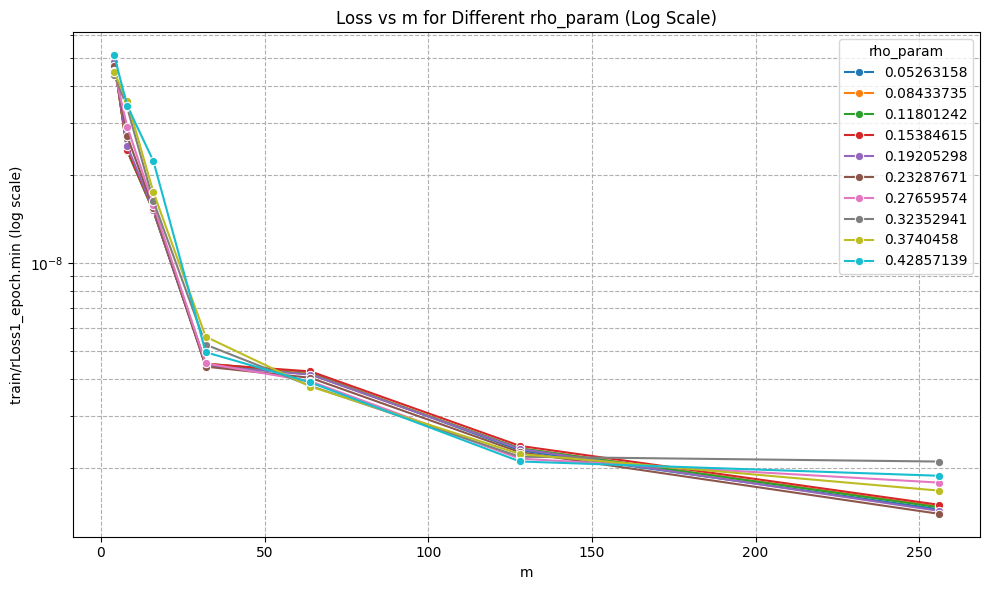

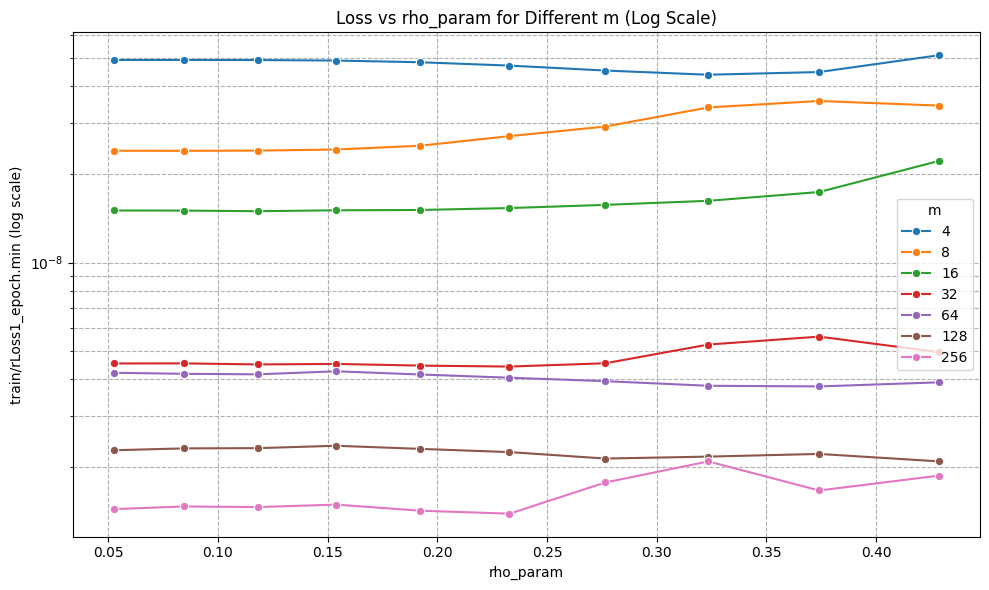

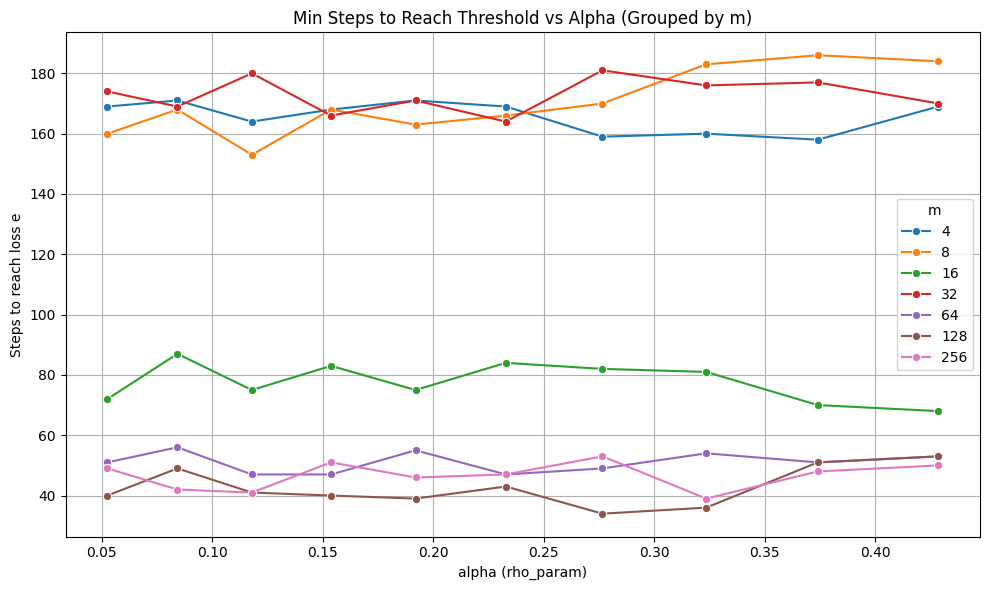

In [10]:
plot_basic('LSTM_exp_step3', 'LSTM', legend1=True, e=1e-7)

## LSTM Polynomial

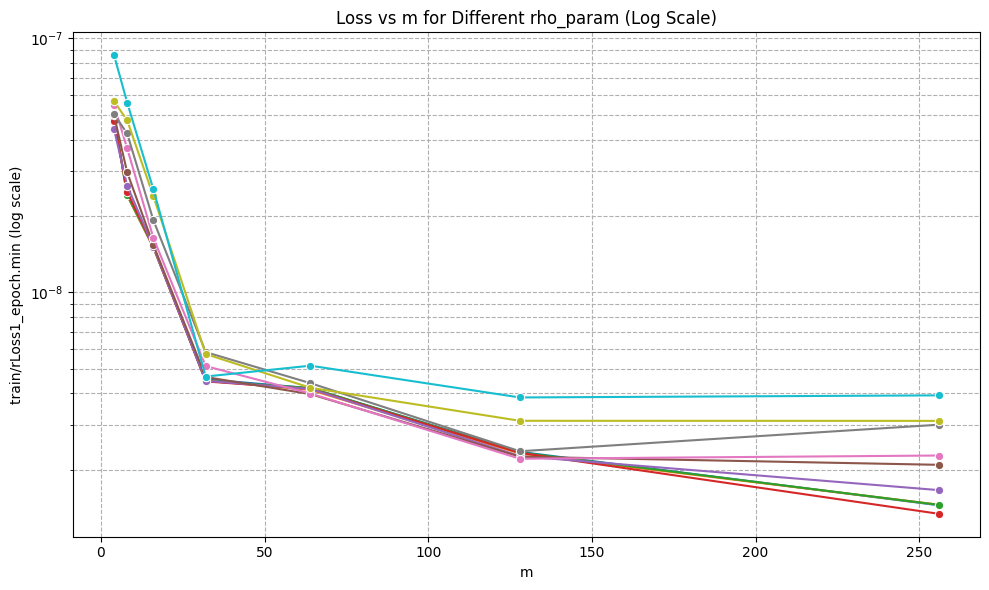

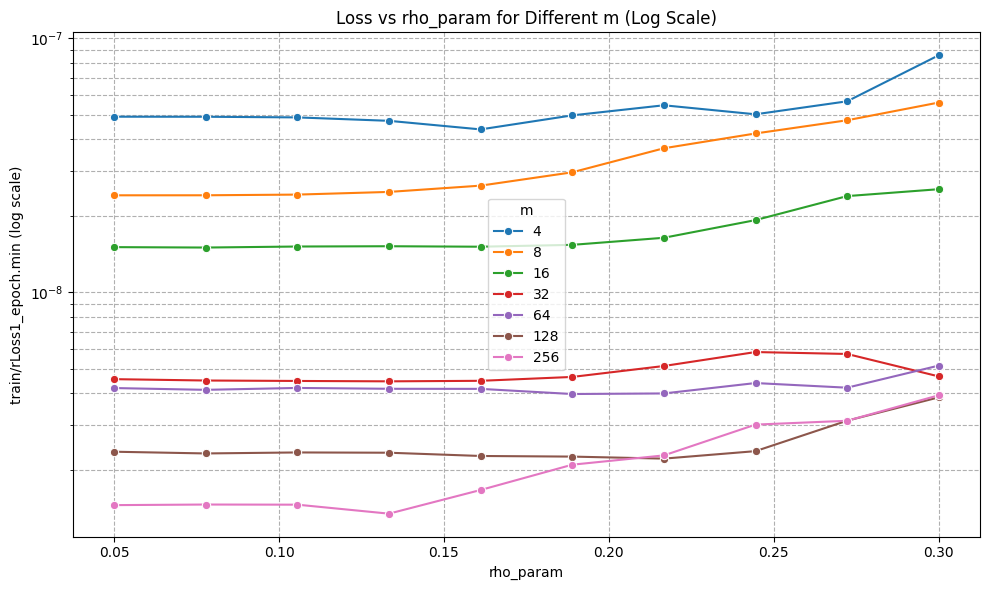

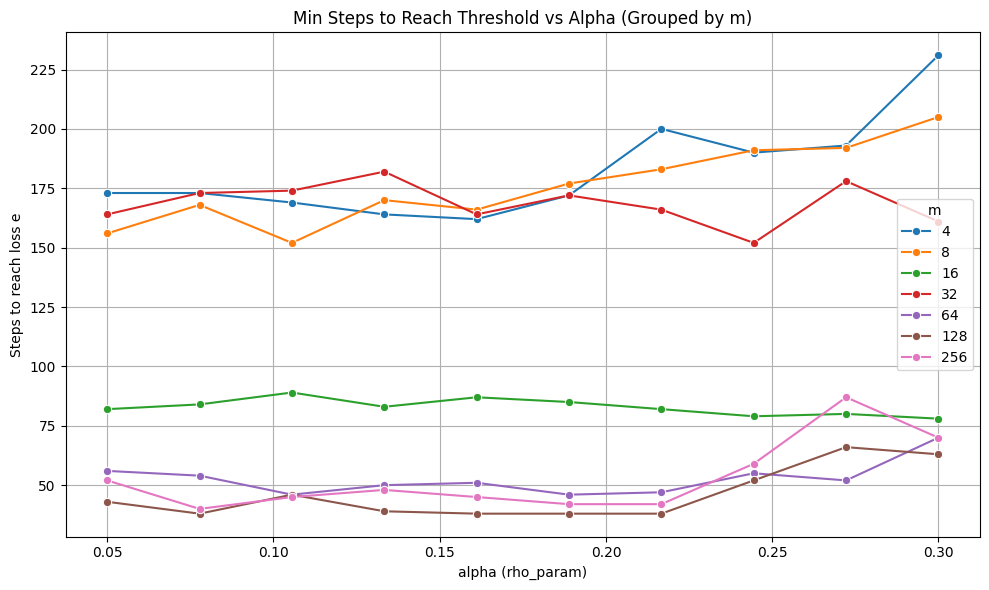

In [11]:
plot_basic('LSTM_poly_step3', 'LSTM', legend1=False, e=1e-7)

## LSTM impulse

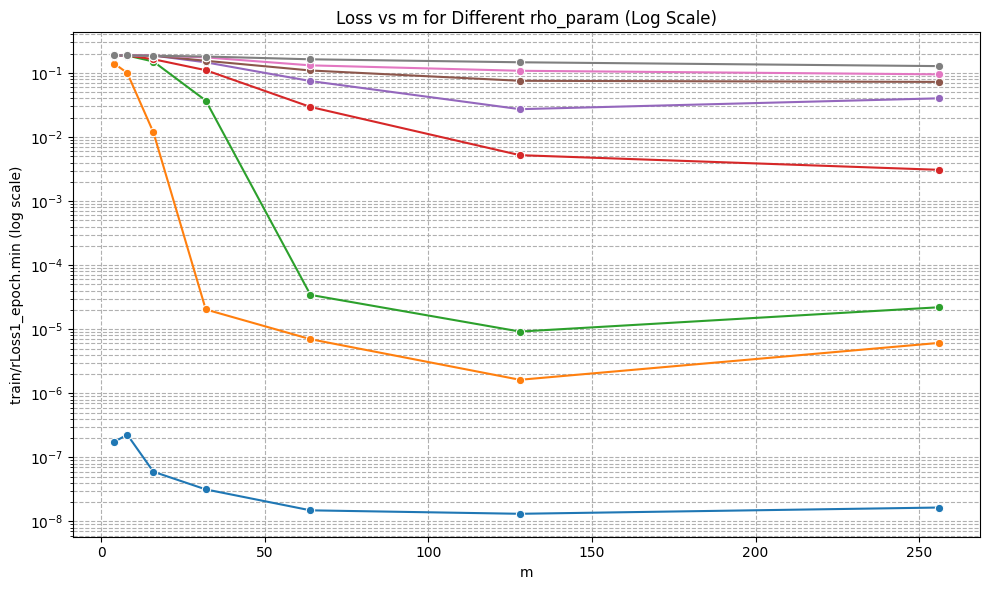

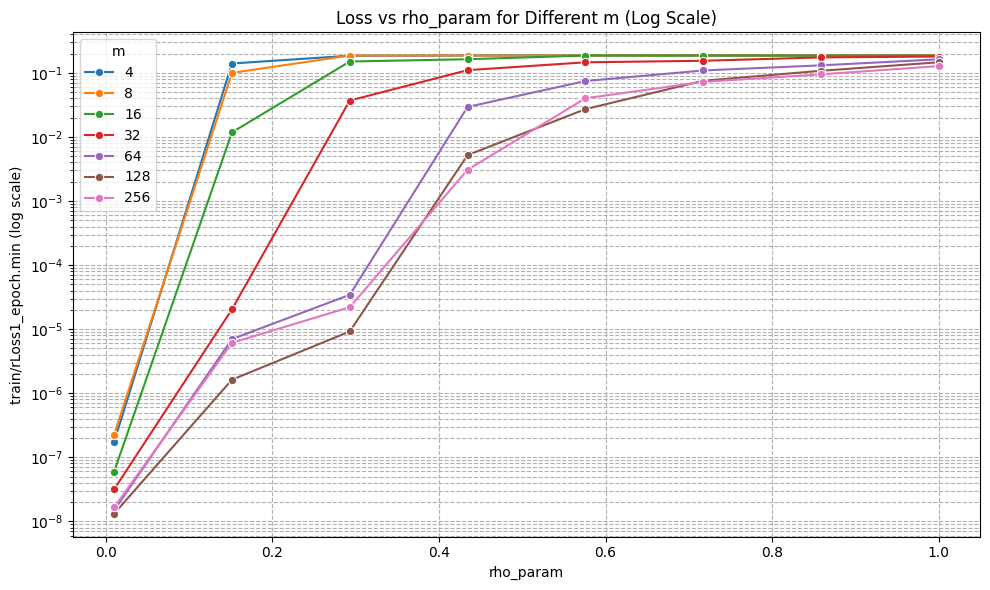

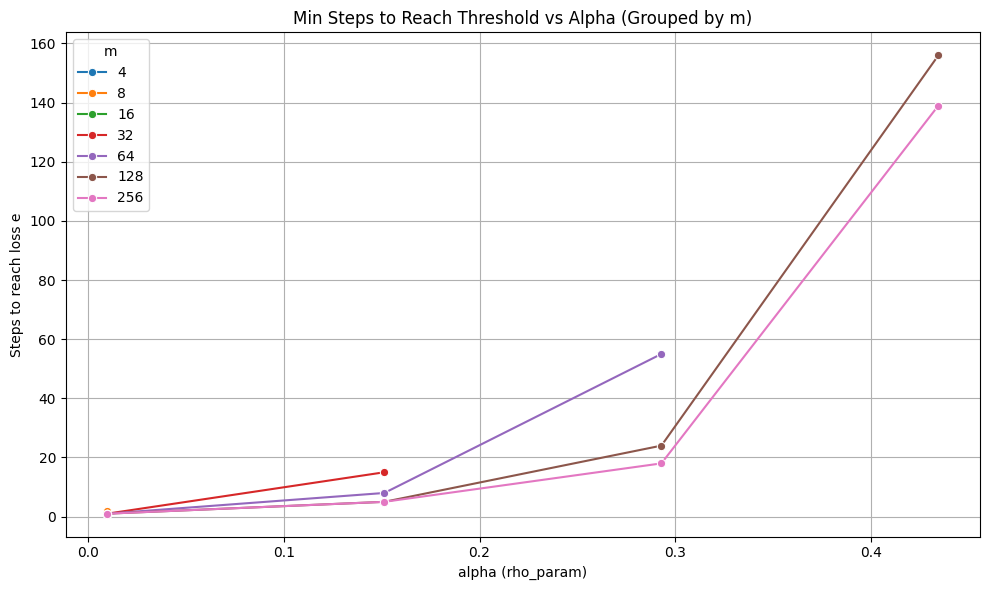

In [12]:
plot_basic('LSTM_impulse_step3', 'LSTM', legend1=False, e=1e-2)

## LSTM Airy

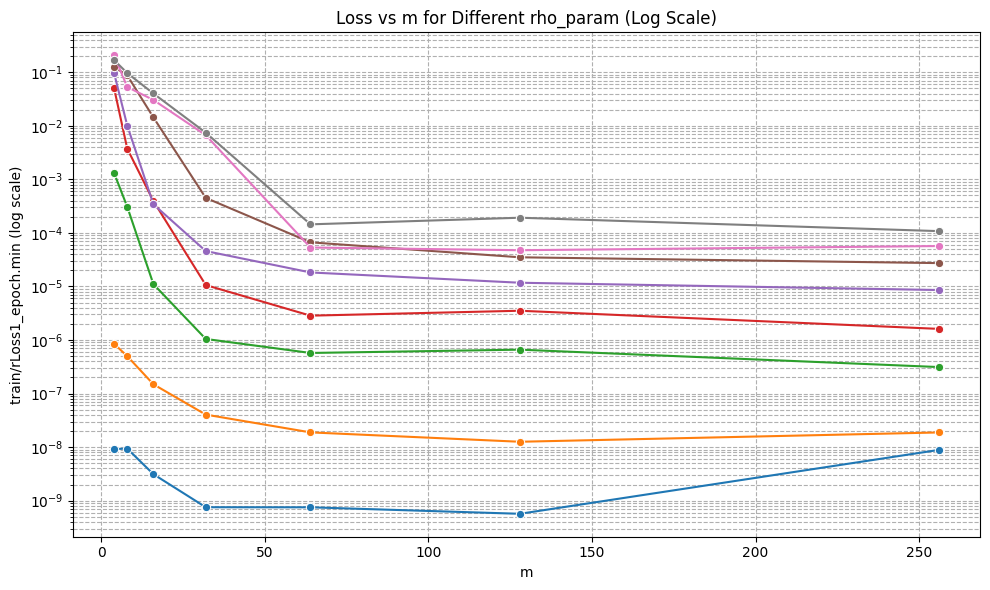

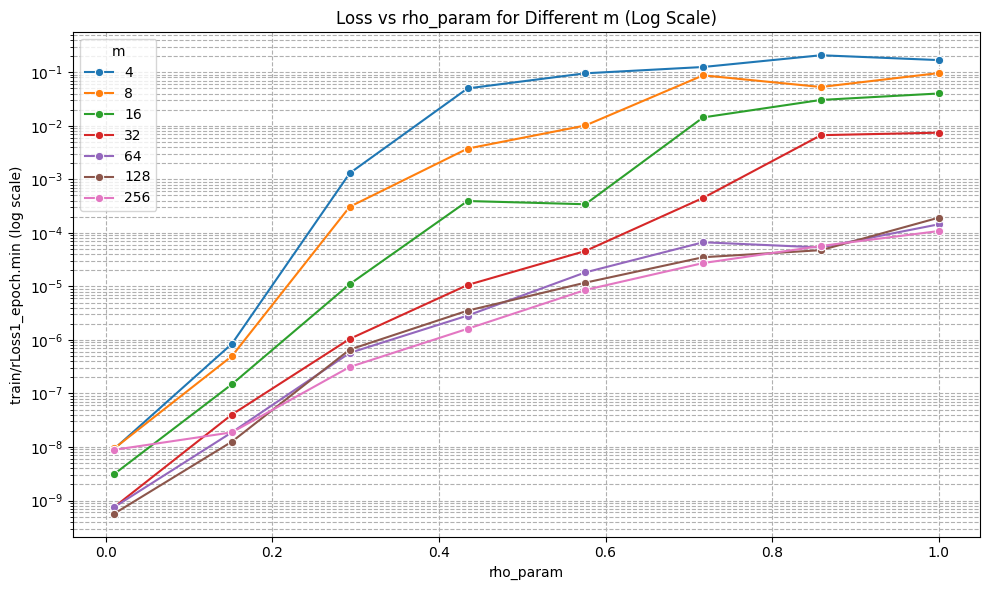

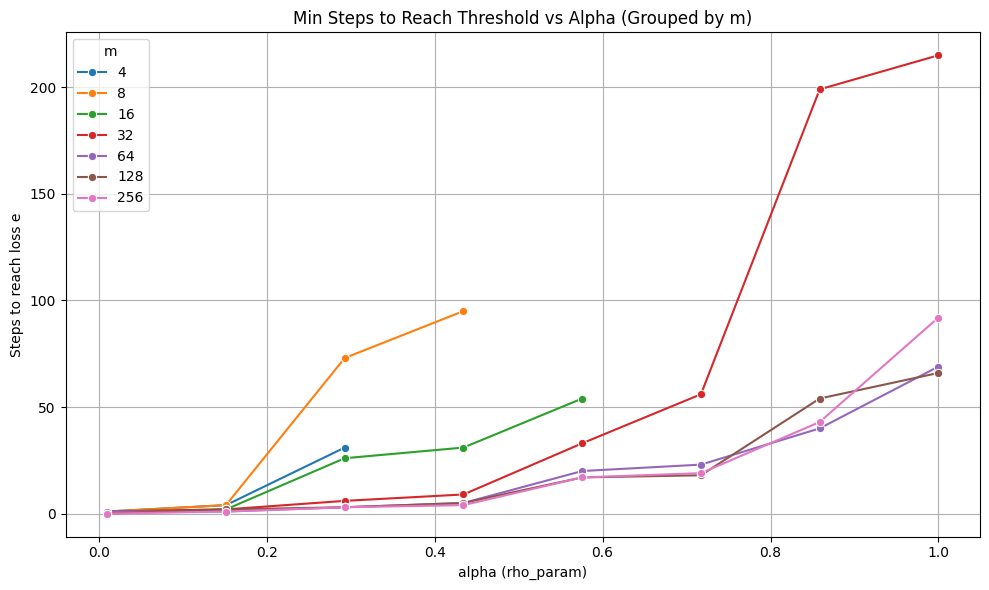

In [13]:
plot_basic('LSTM_airy_step3', 'LSTM', legend1=False, e=1e-2)

# S4

## S4 Exp

In [14]:
# df = pd.read_pickle(f"S4_exp_step1_data_clean.pkl")
# [d for d in df.columns];

/tmp/ipykernel_2416047/3970028317.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


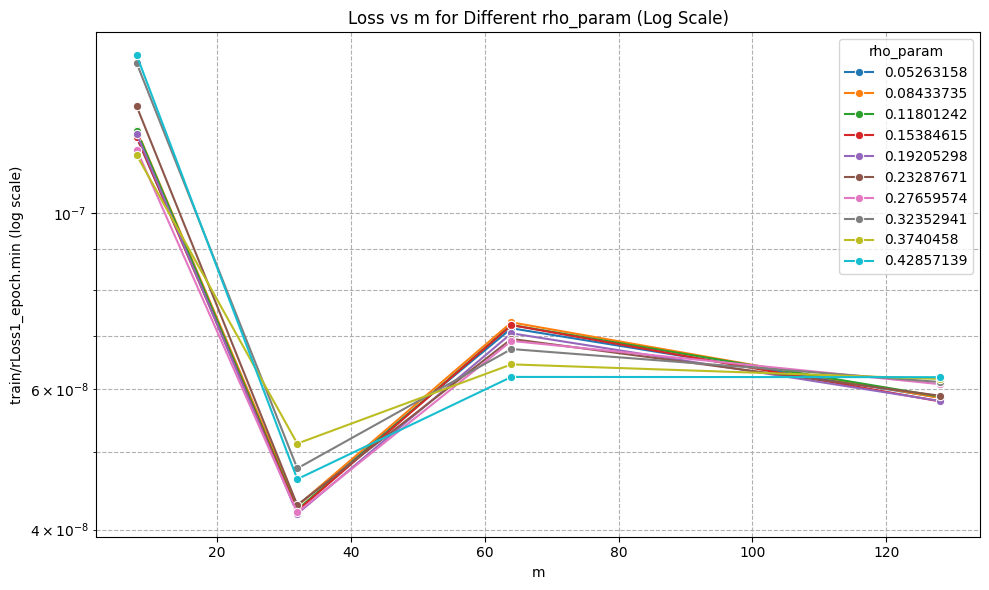

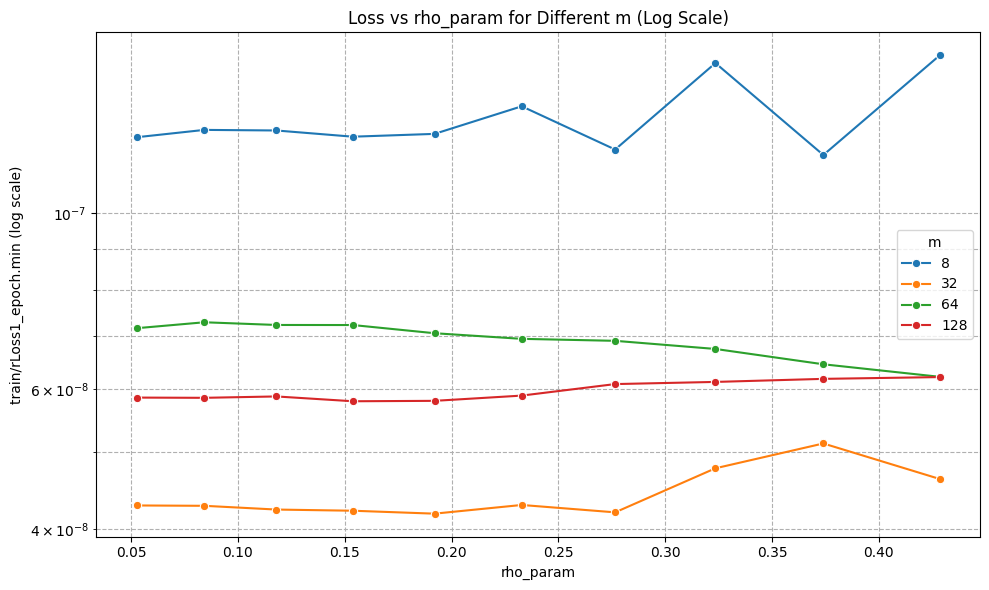

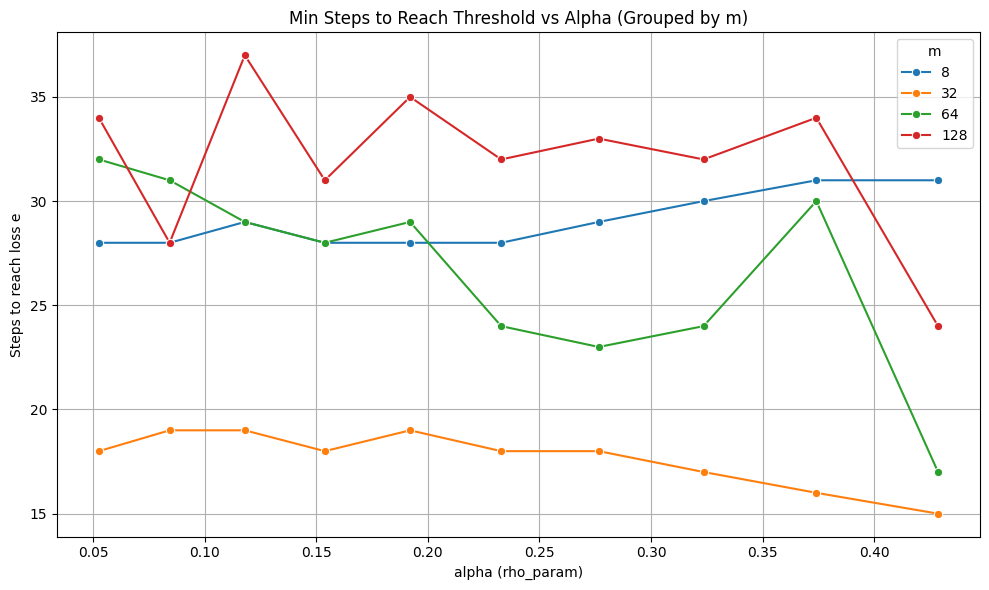

In [26]:
plot_basic('S4_exp_step3', 'S4', legend1=True, e=1e-5, conditions=[('m>4'),('m!=16')])

## S4 Polynomial

/tmp/ipykernel_2416047/3970028317.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


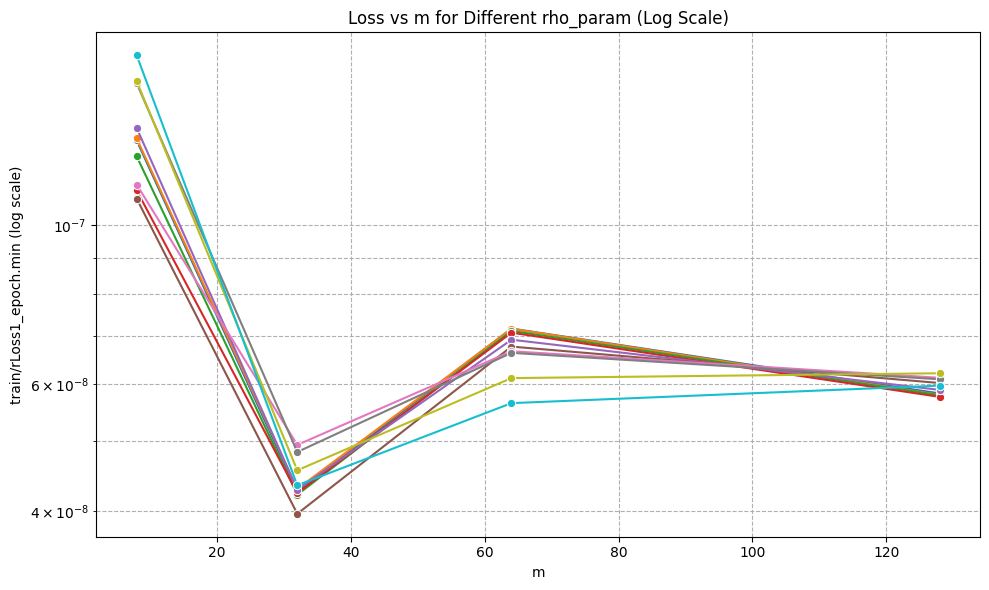

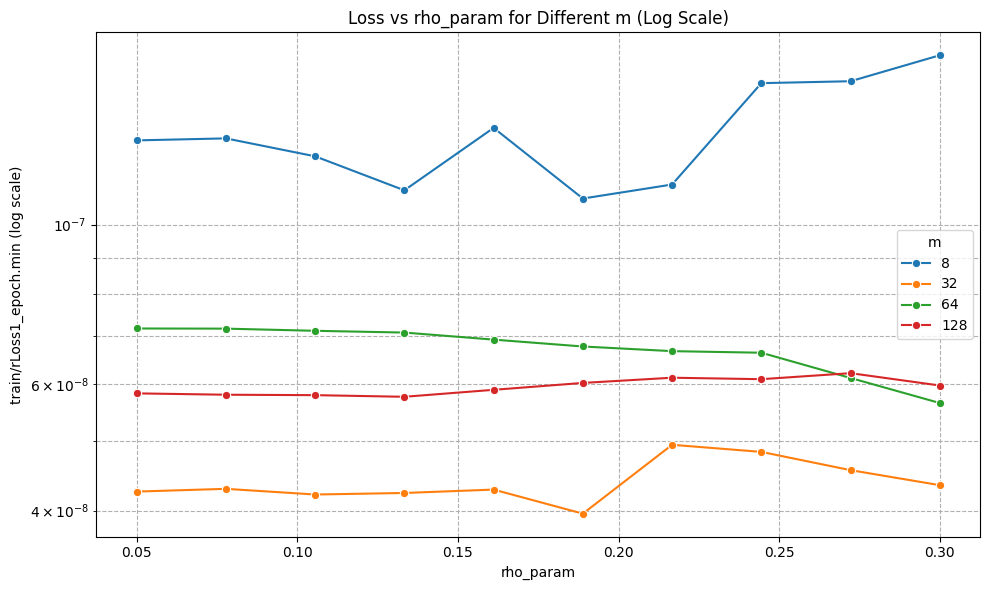

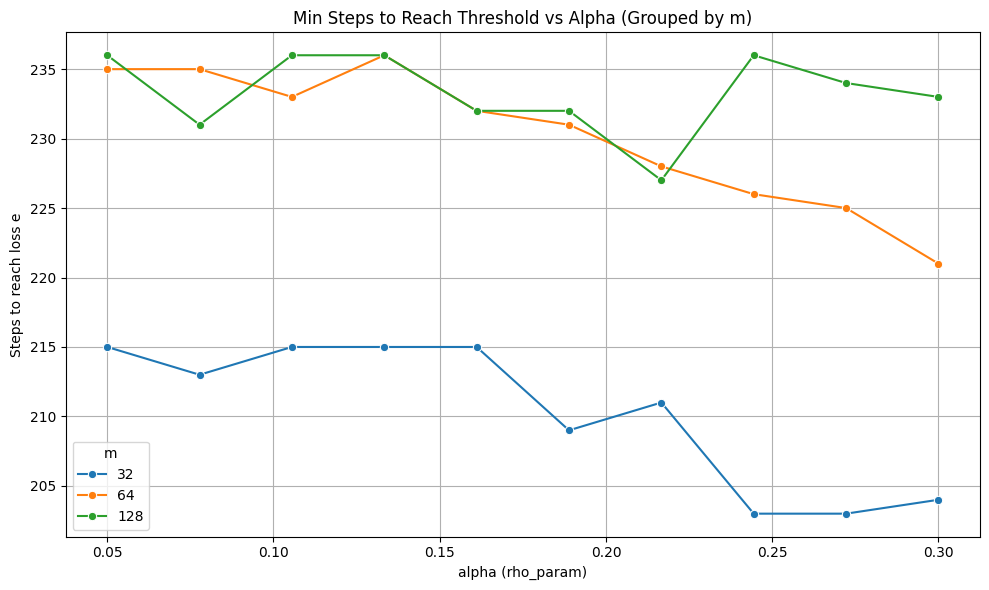

In [28]:
plot_basic('S4_poly_step3', 'S4', legend1=False, e=1e-7,conditions=[('m>4'),('m!=16')])

## S4 impulse

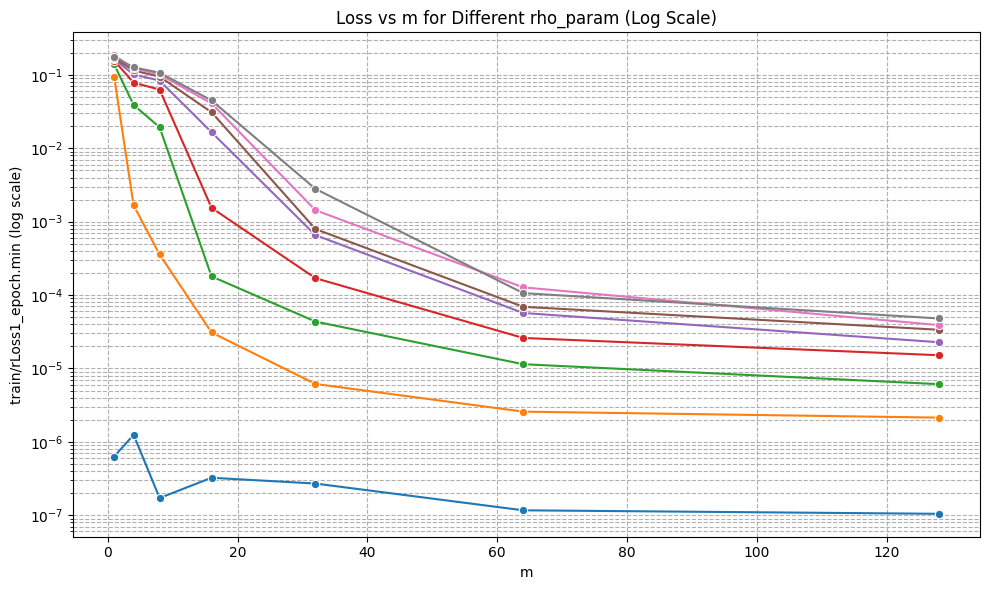

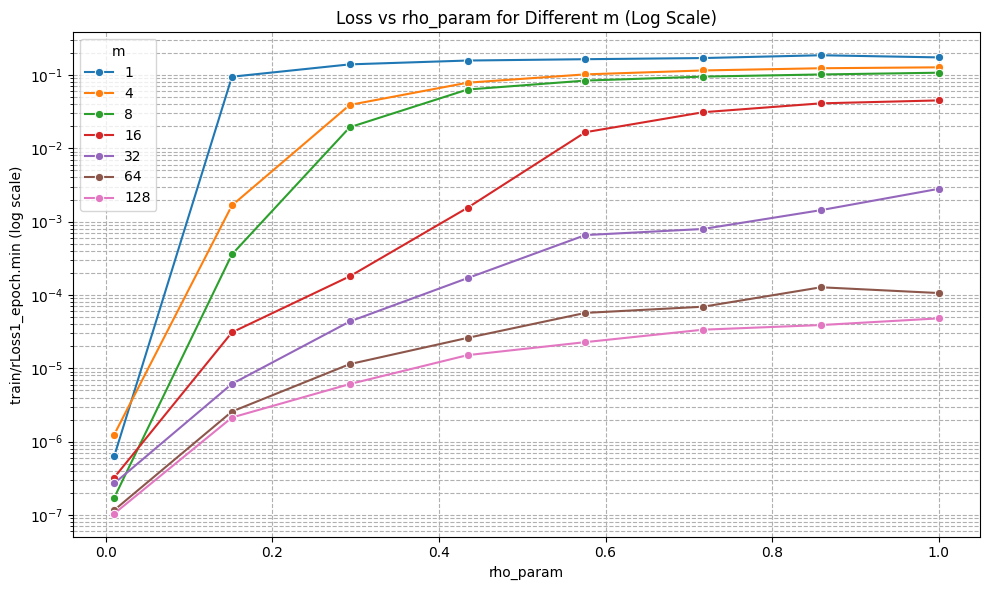

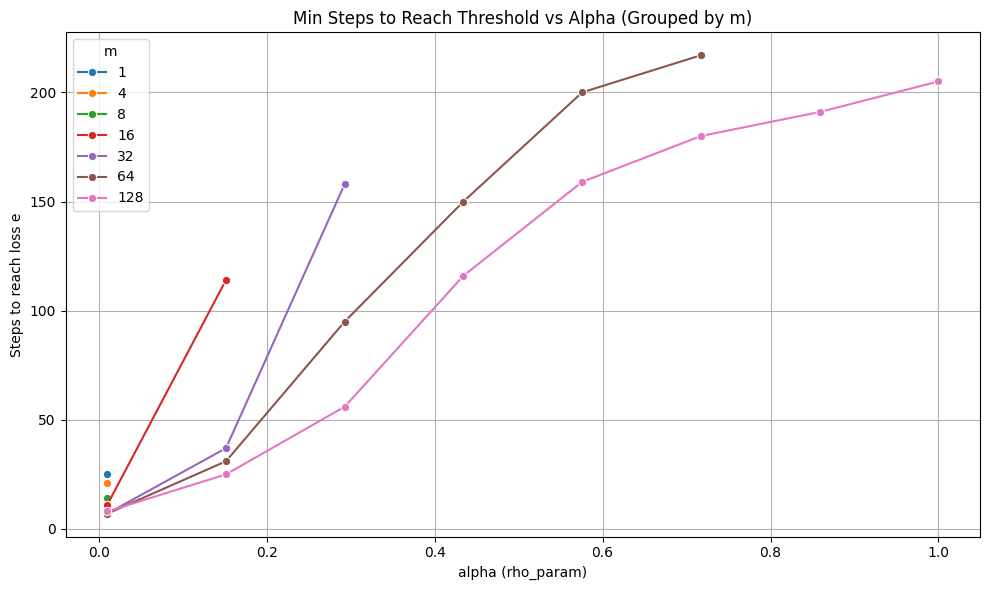

In [30]:
plot_basic('S4_impulse_step3', 'S4', legend1=False, e=1e-4)

## S4 Airy

/tmp/ipykernel_2416047/3970028317.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


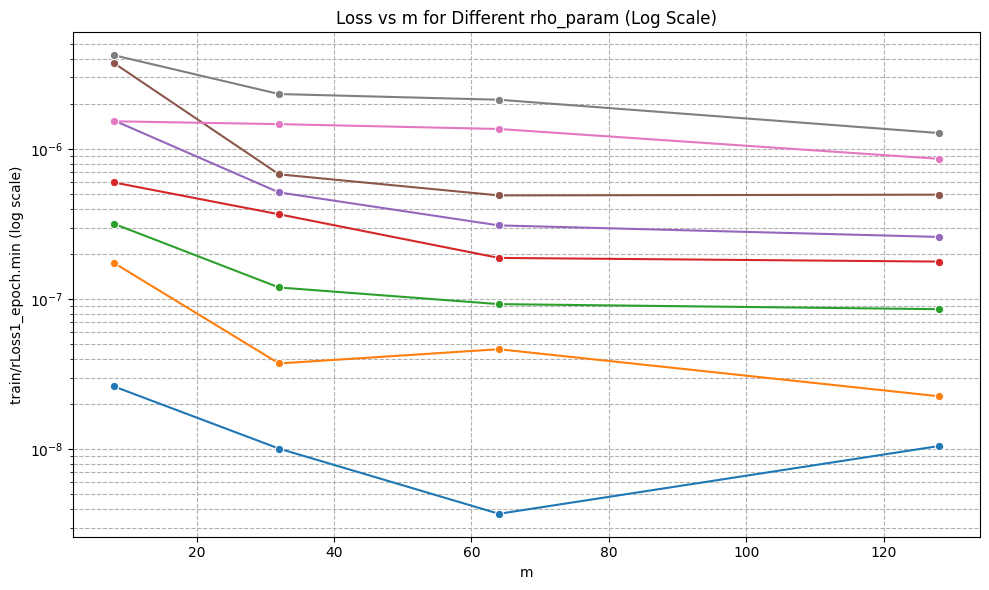

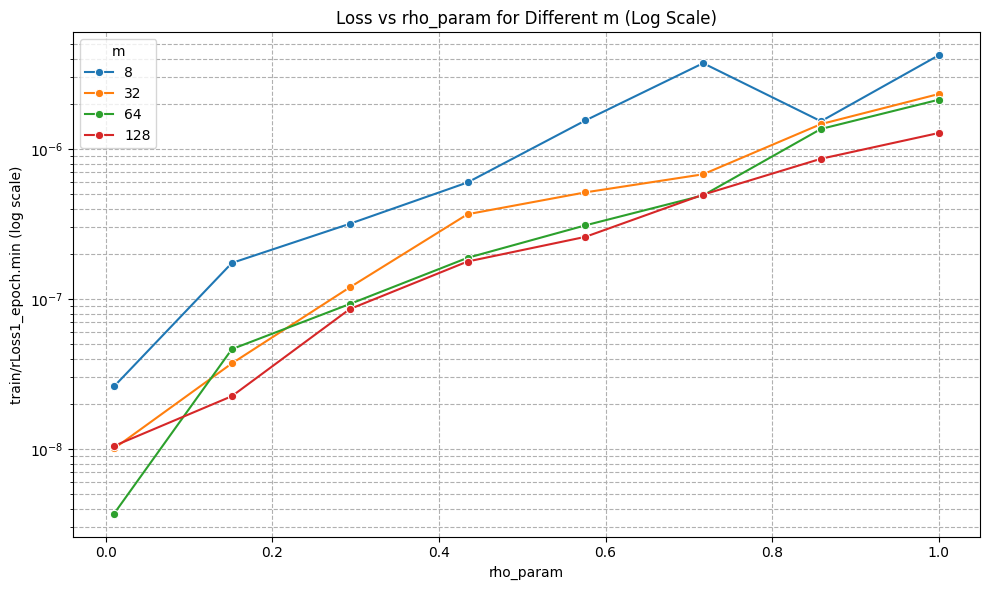

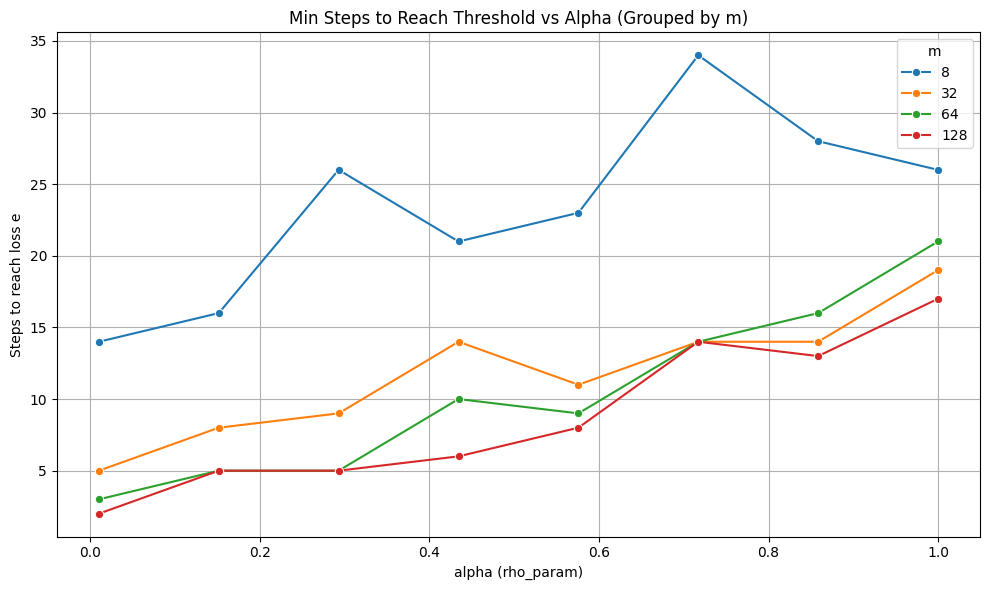

In [32]:
plot_basic('S4_airy_step3', 'S4', legend1=False, e=1e-4, conditions=[('m>4'),('m!=16')])

# TCN

## TCN Exp

/tmp/ipykernel_2416047/3970028317.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


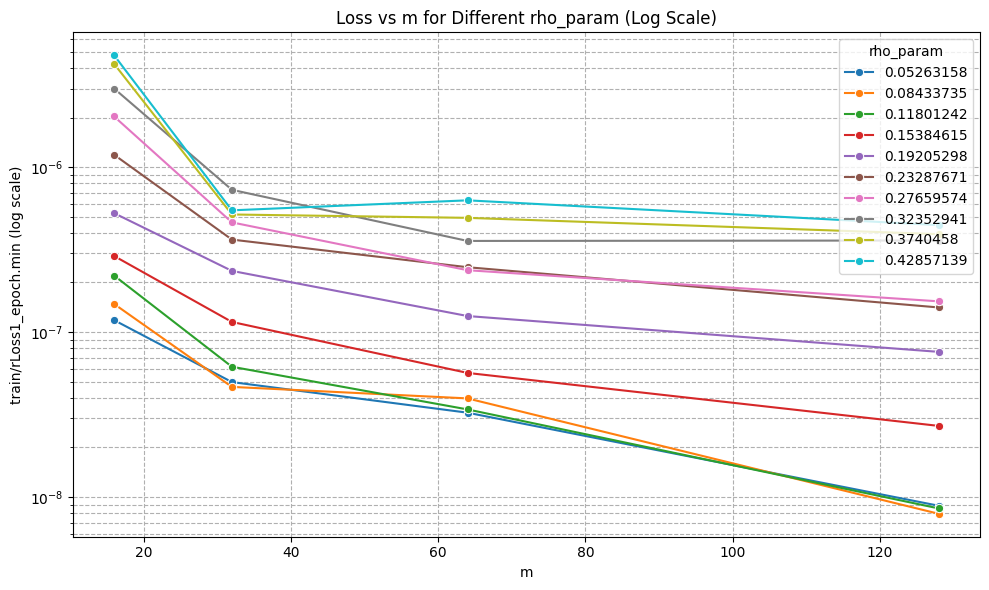

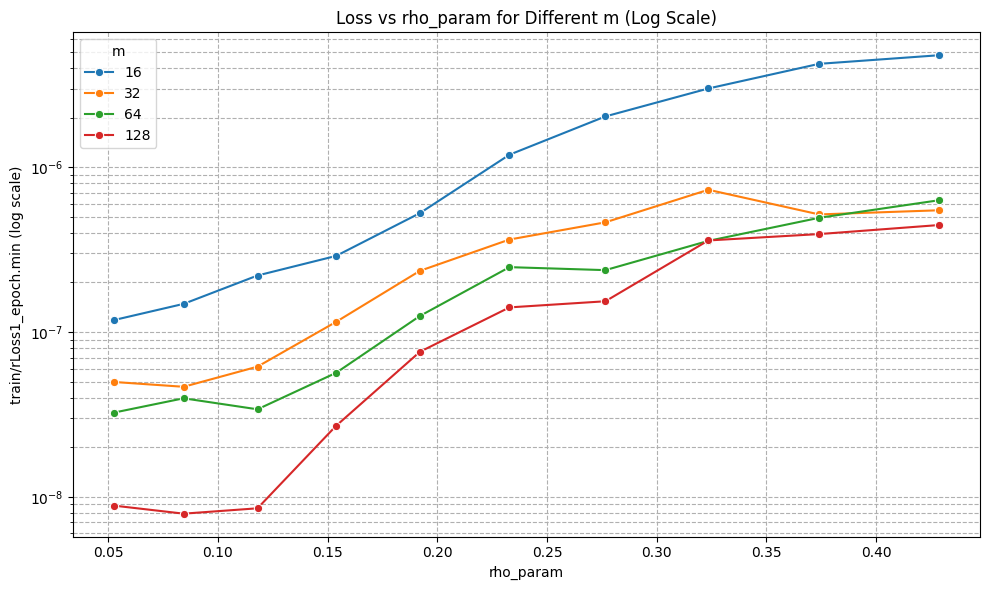

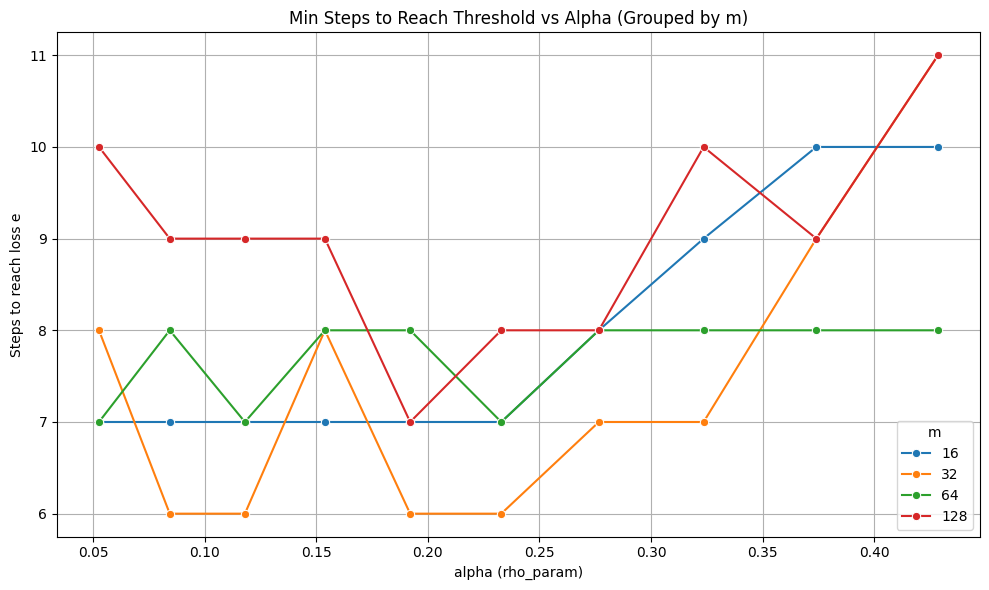

In [35]:
plot_basic('TCN_exp_step3', 'TCN', legend1=True, e=1e-4, conditions=[('m>8')])

## TCN Polynomial

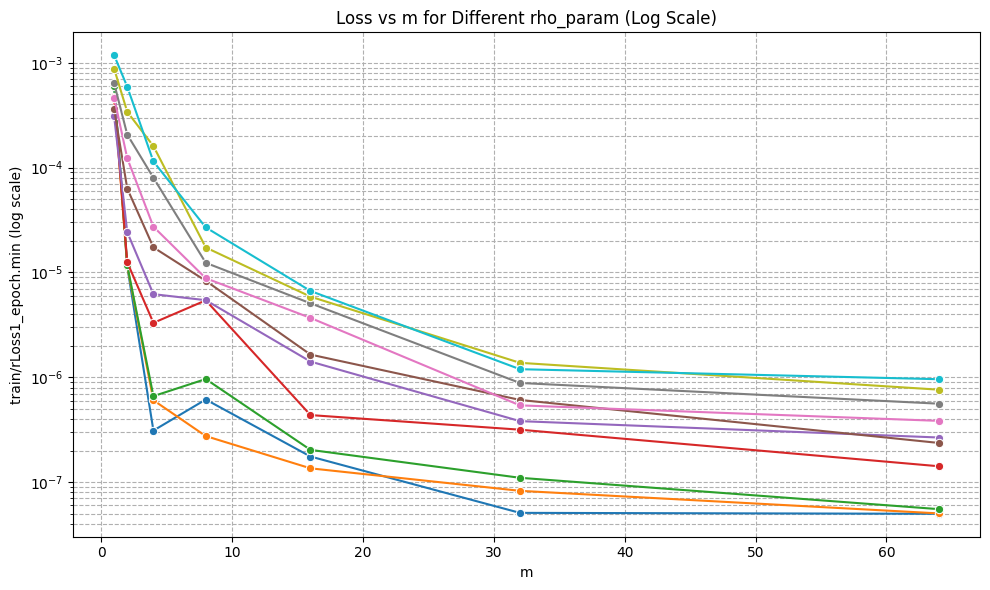

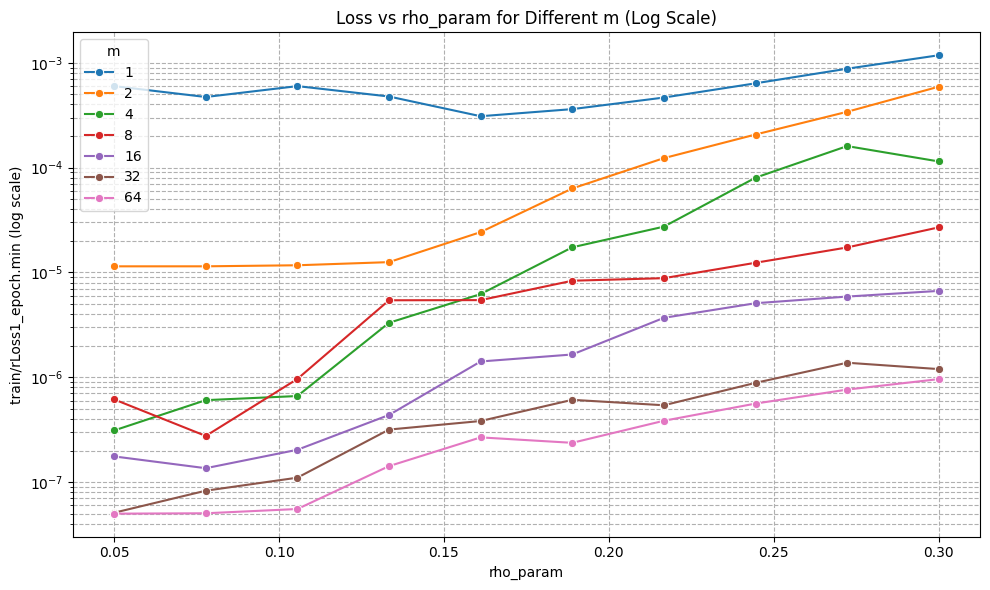

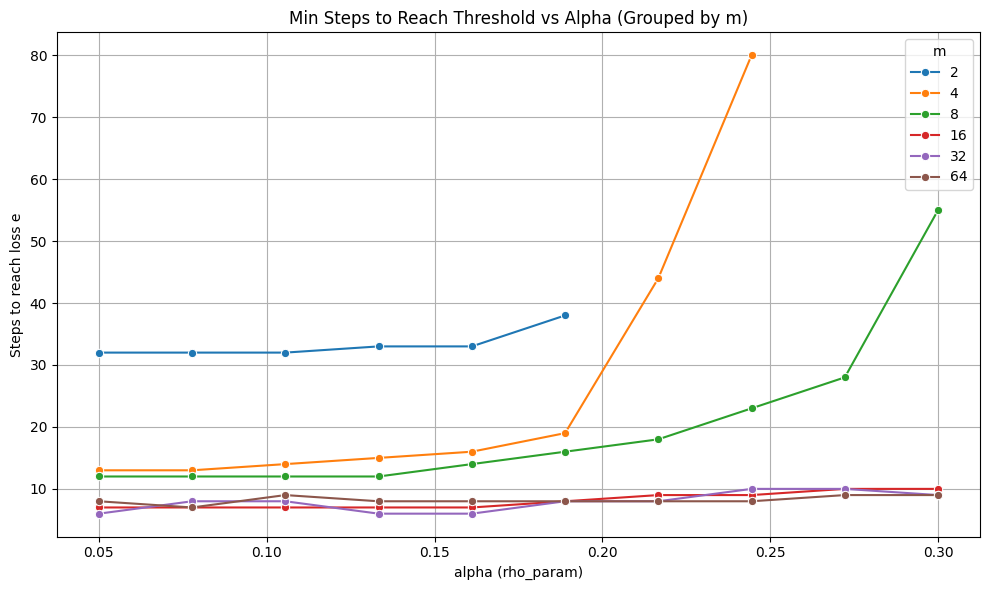

In [39]:
plot_basic('TCN_poly_step3', 'TCN', legend1=False, e=1e-4)

## TCN impulse

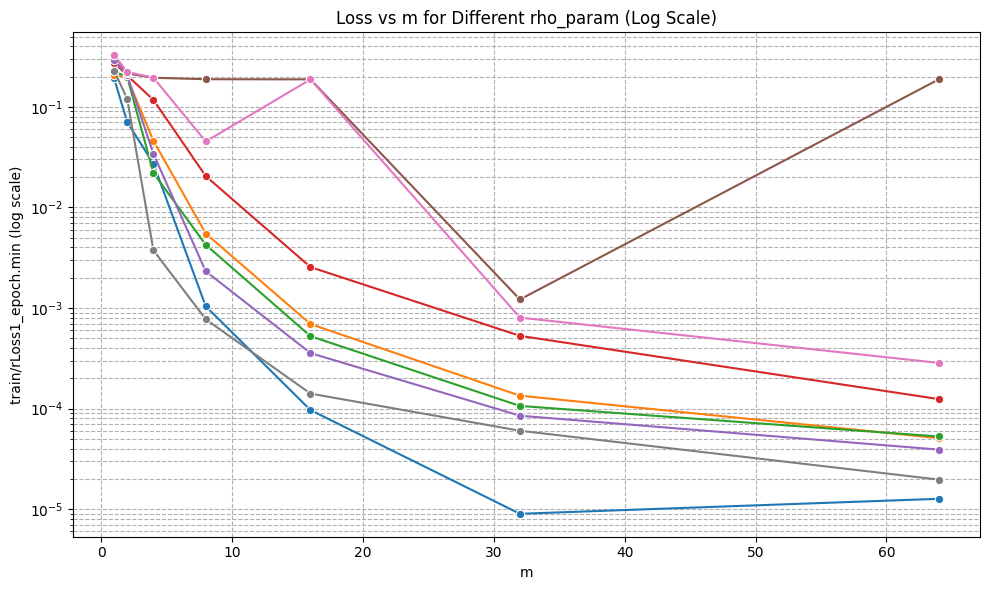

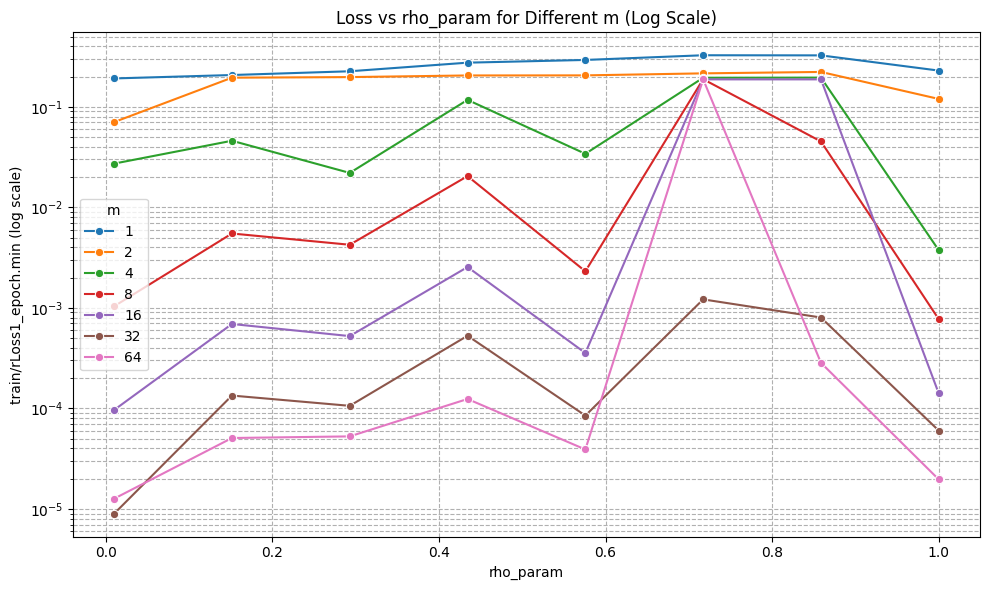

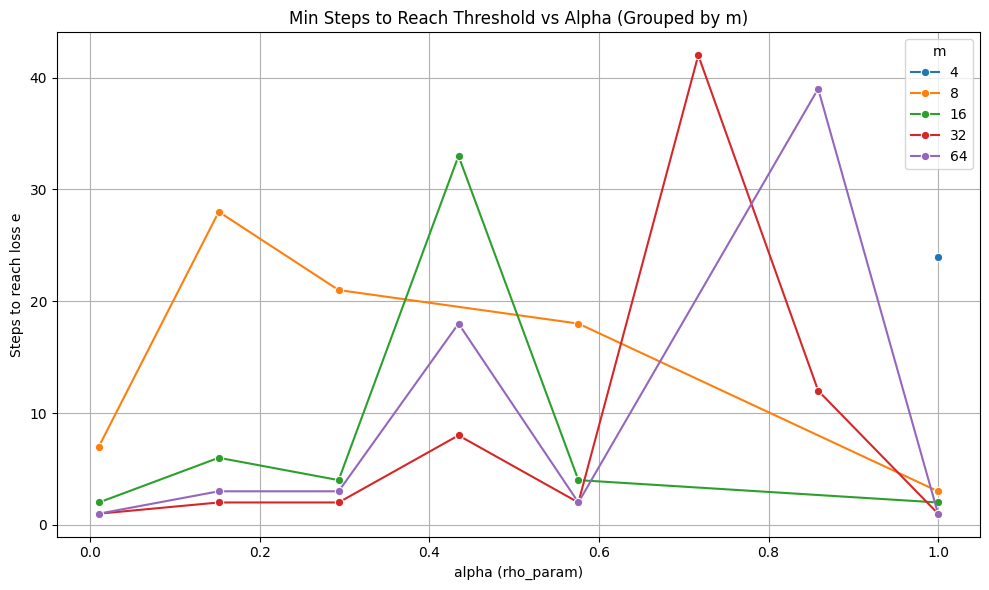

In [37]:
plot_basic('TCN_impulse_step3', 'TCN', legend1=False, e=1e-2)

## TCN Airy

/tmp/ipykernel_2416047/3970028317.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


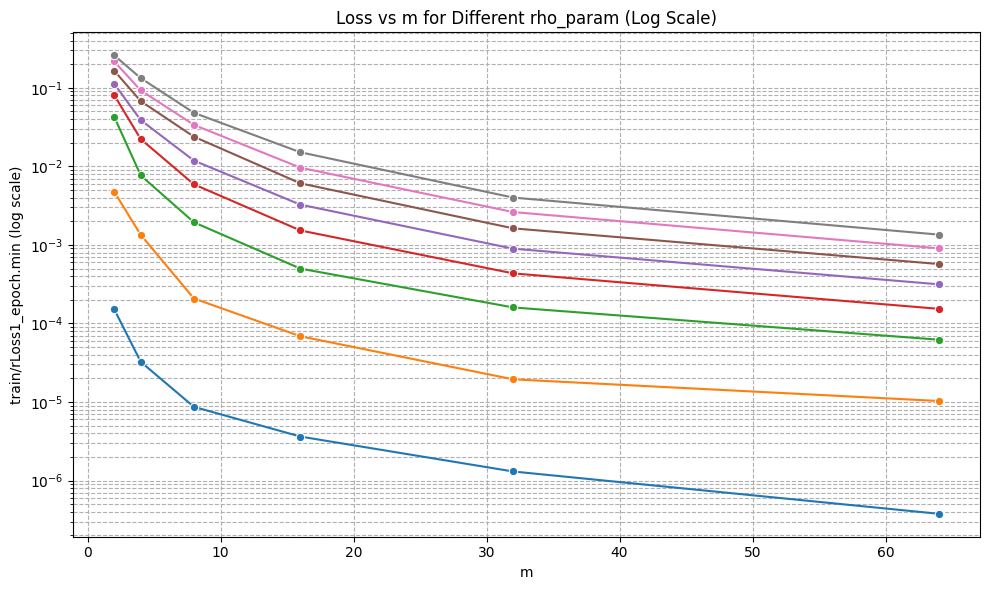

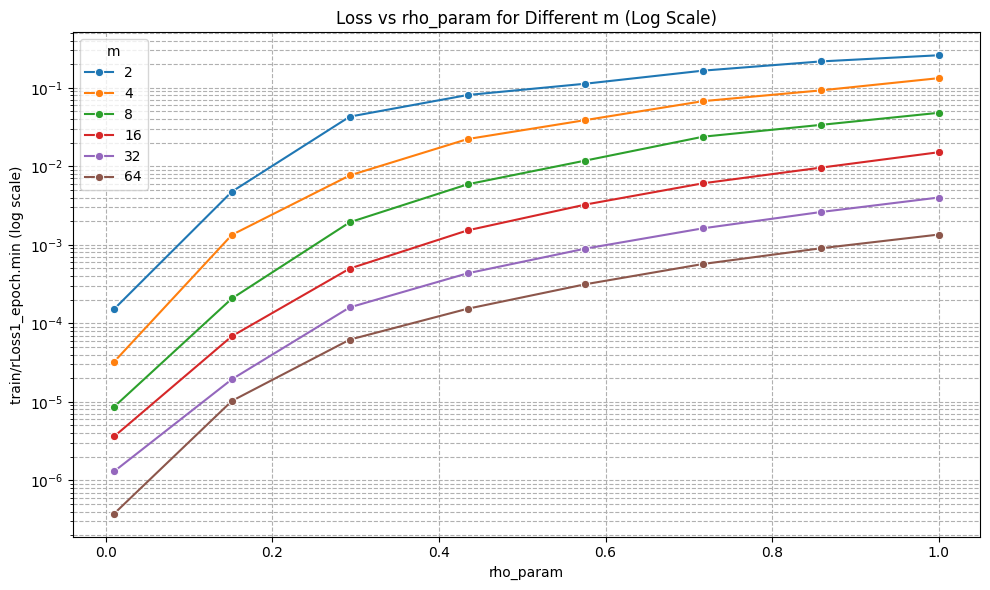

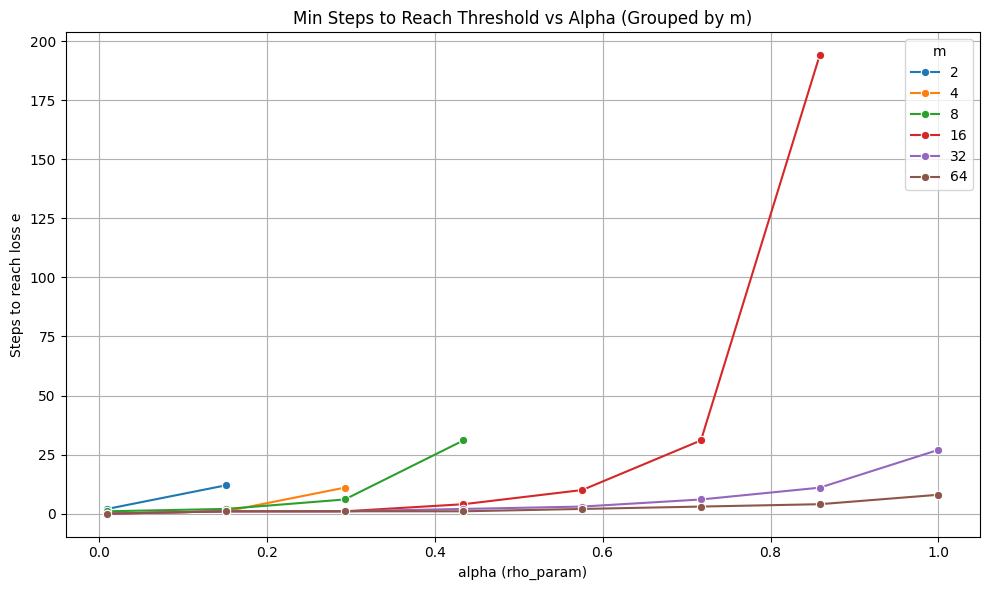

In [38]:
plot_basic('TCN_airy_step3', 'TCN', legend1=False, e=1e-2, conditions=[('m>1')])

# Transformer

## Transformer Exp

In [53]:
df = pd.read_pickle(f"Transformer_exponential_step1_data_clean.pkl")
[d for d in df.columns];
# module.layers.Layer1.nhead
# module.layers.Layer1.hid_dim

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


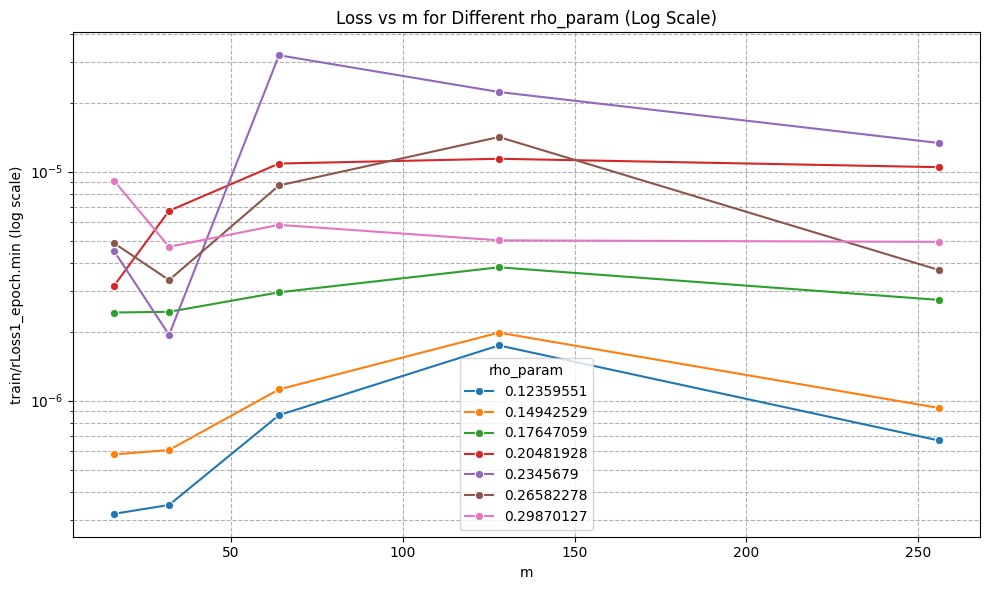

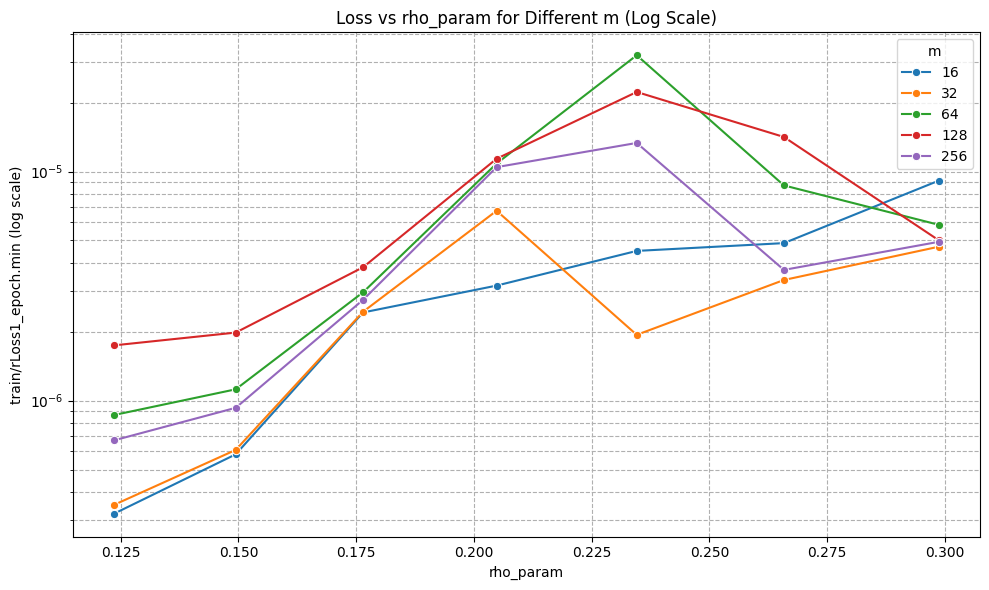

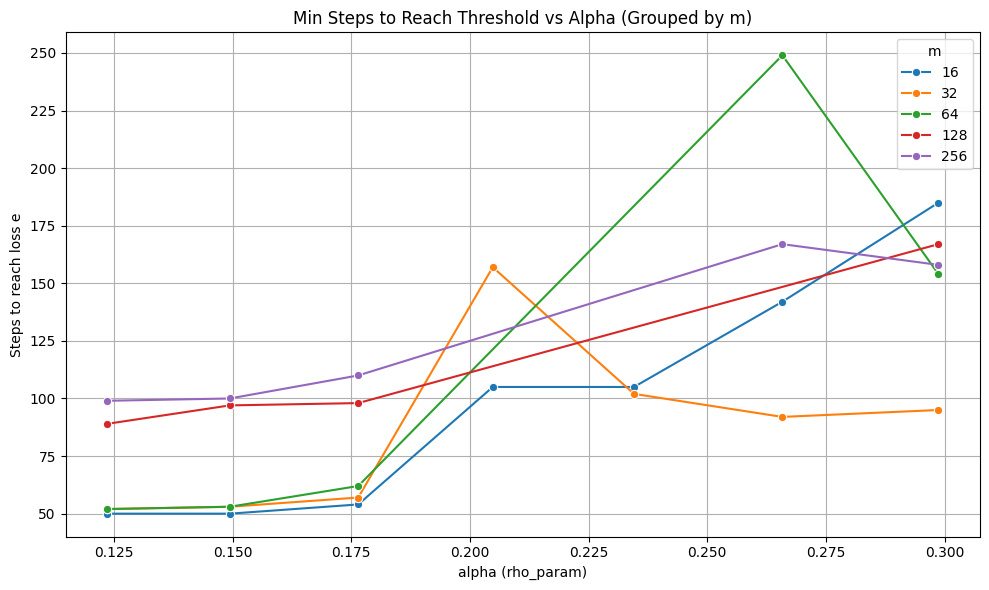

In [58]:
plot_basic('Transformer_exponential_step3', 'Trans_hid_dim', legend1=True, e=1e-5, conditions=["`module.layers.Layer1.nhead`==1", "m>1", "`data.rho_param.alpha`>=0.1"])

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


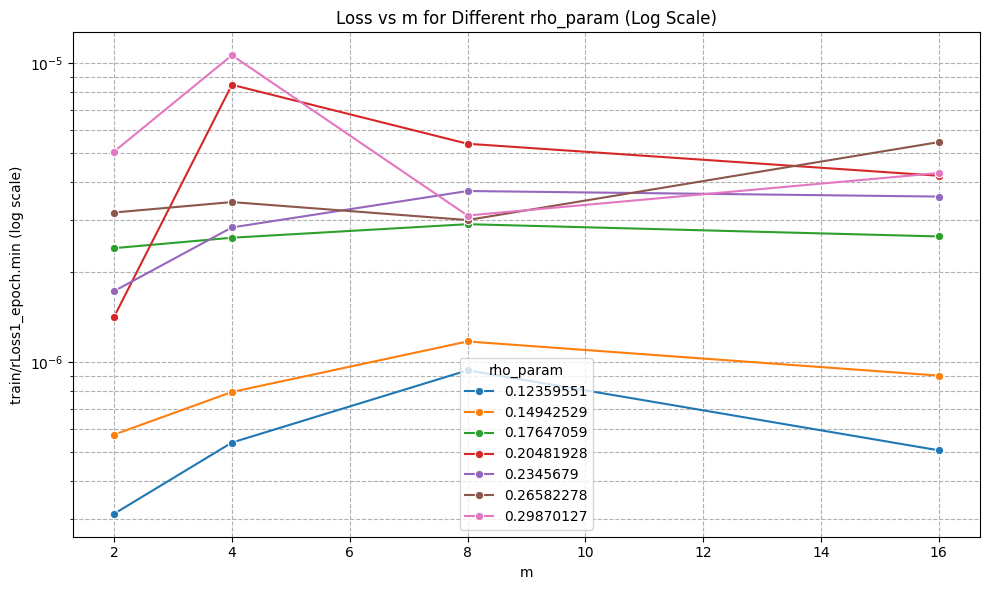

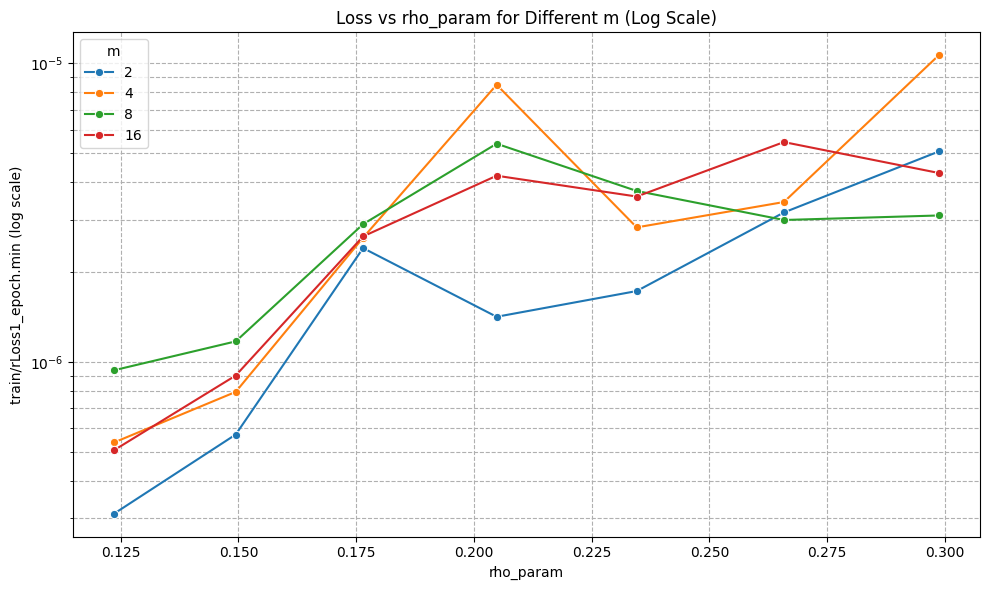

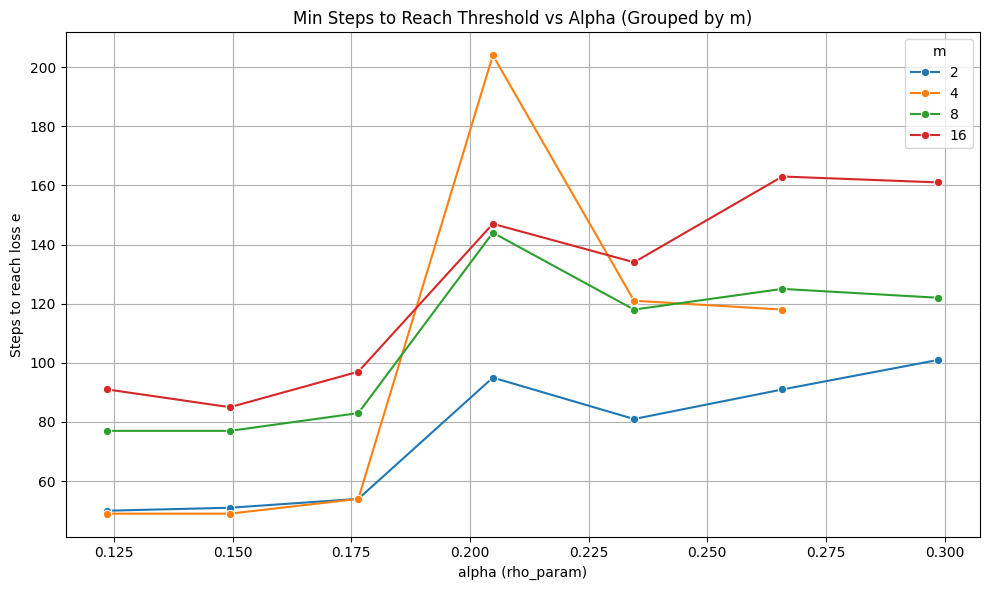

In [60]:
plot_basic('Transformer_exponential_step3', 'Trans_nhead', legend1=True, e=1e-5, conditions=[ "m>1", "`data.rho_param.alpha`>=0.1"])

## Transformer Polynomial

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


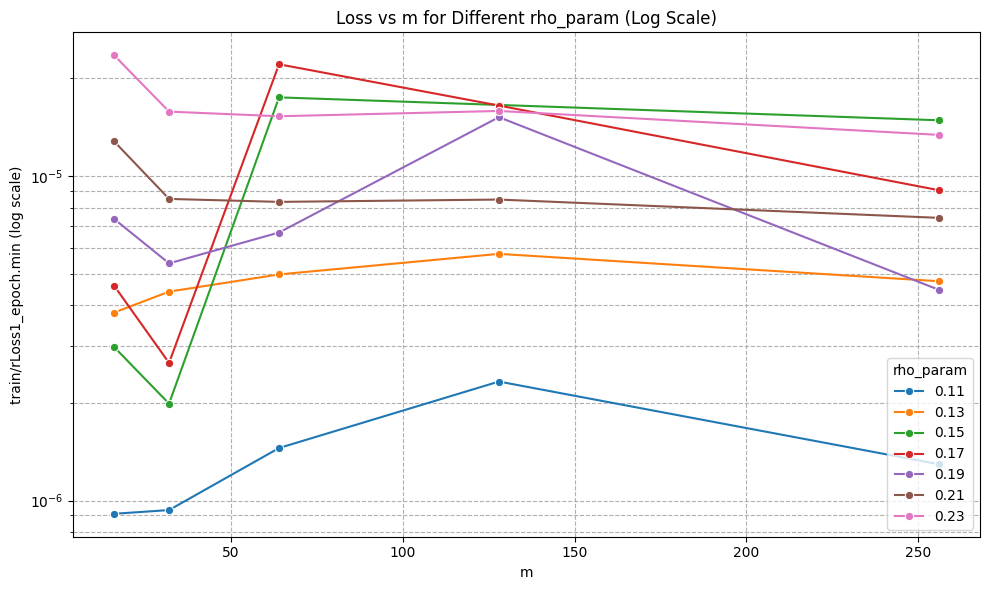

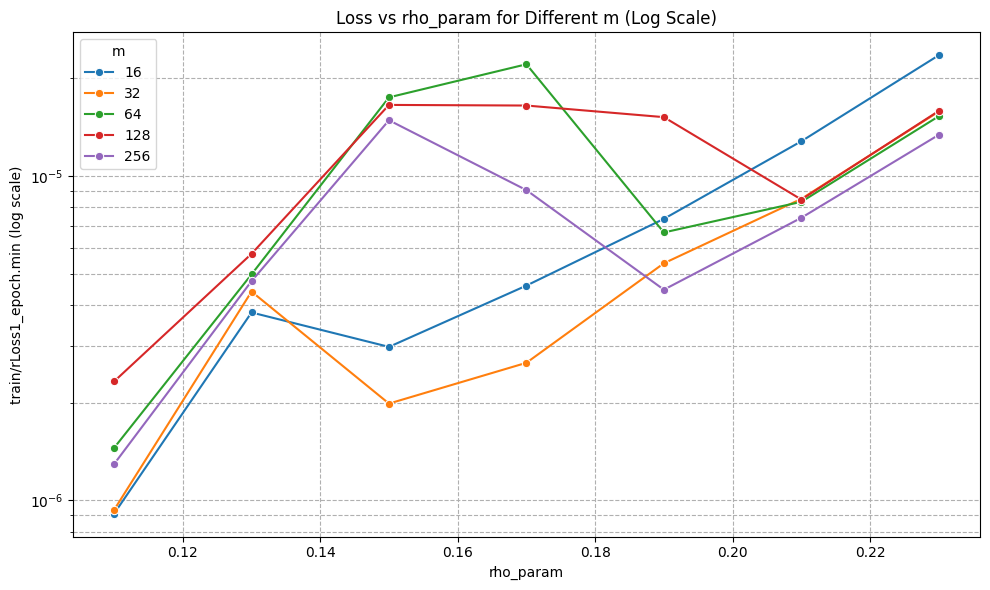

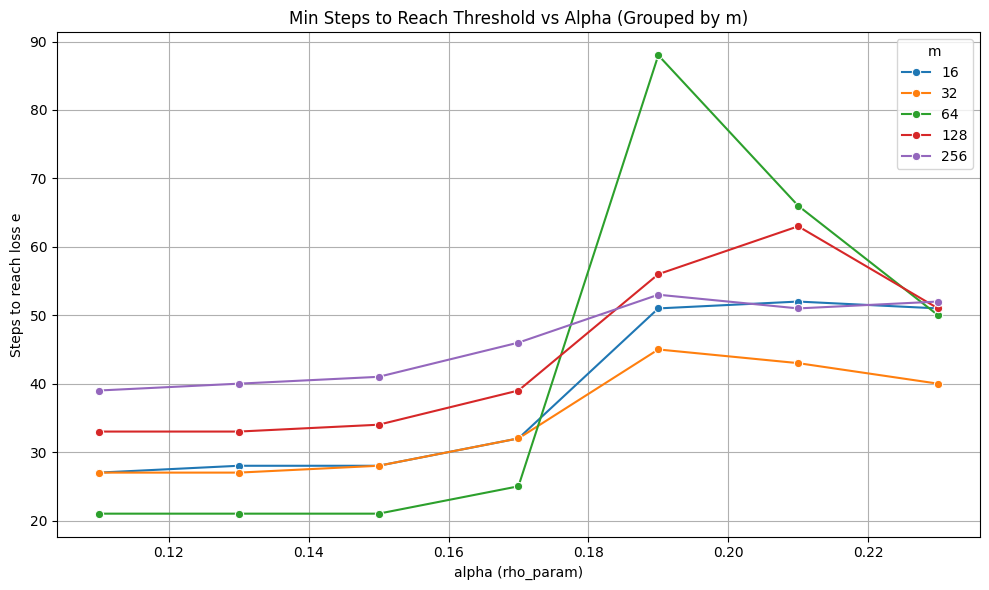

In [59]:
plot_basic('Transformer_polynomial_step3', 'Trans_hid_dim', legend1=True, e=1e-4, conditions=["`module.layers.Layer1.nhead`==1",'m>4',"`data.rho_param.alpha`>=0.1"])

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


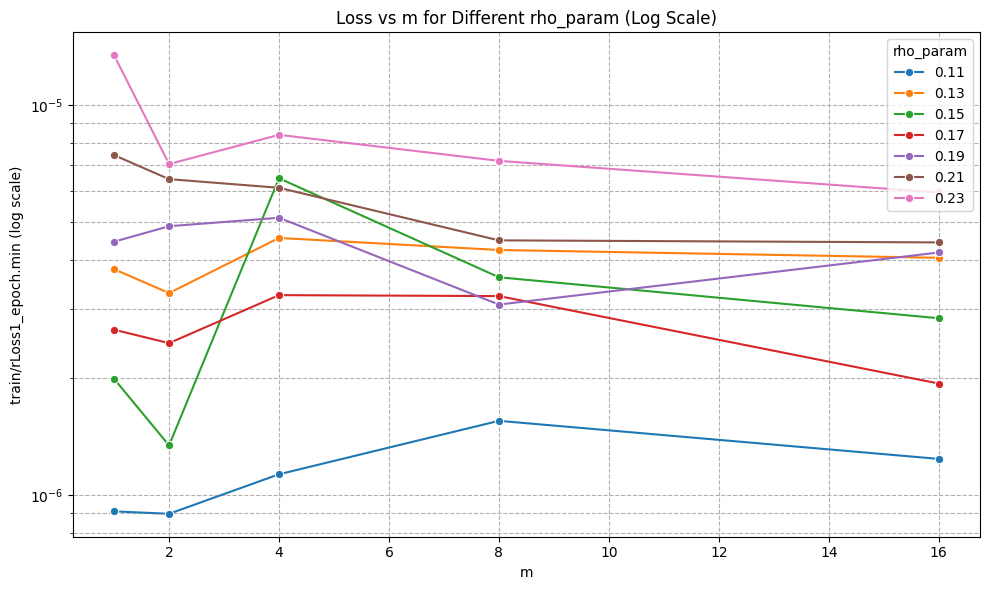

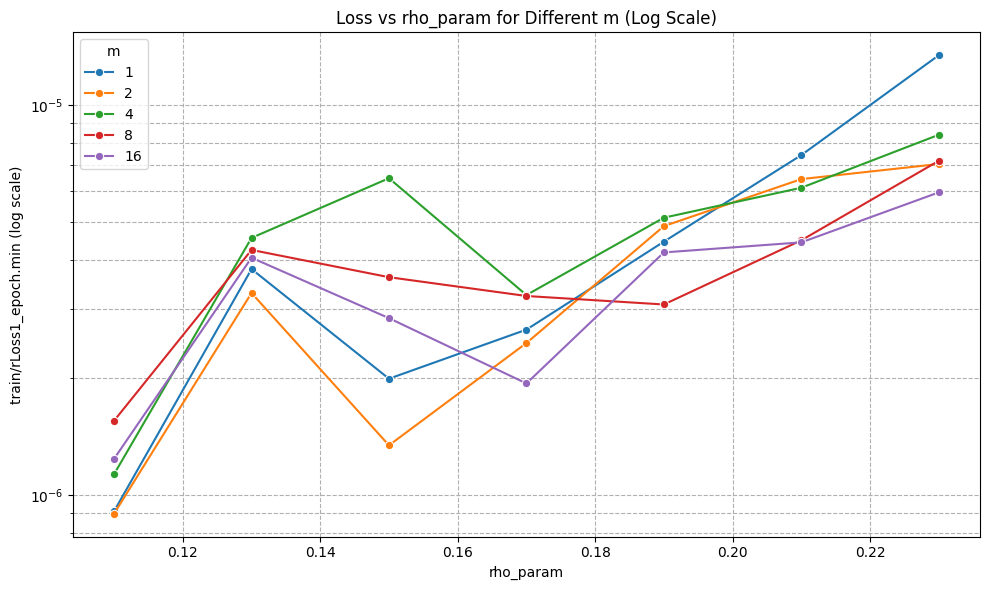

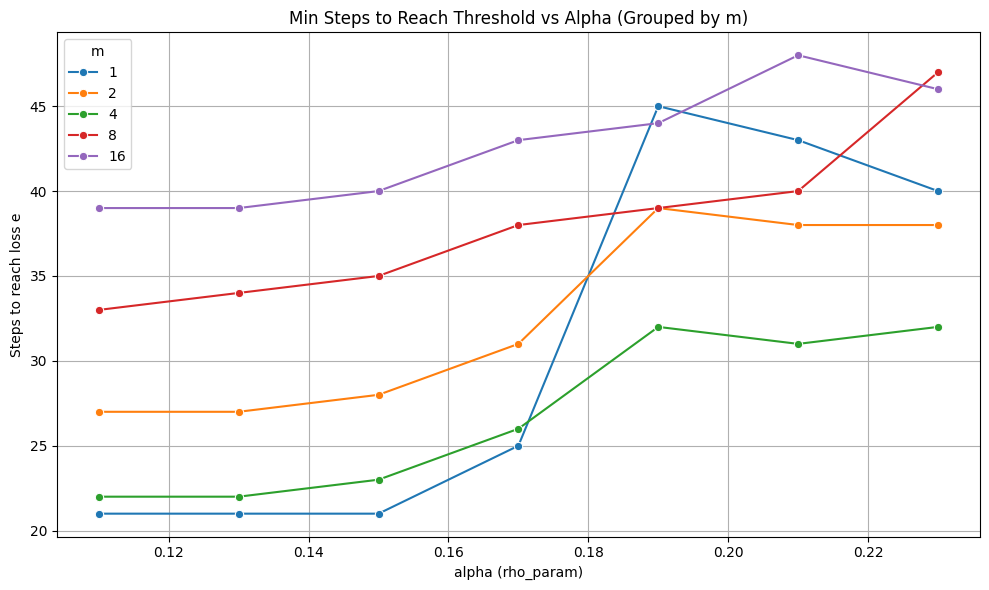

In [62]:
plot_basic('Transformer_polynomial_step3', 'Trans_nhead', legend1=True, e=1e-4, conditions=["`data.rho_param.alpha`>=0.1"])

## Transformer impulse

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


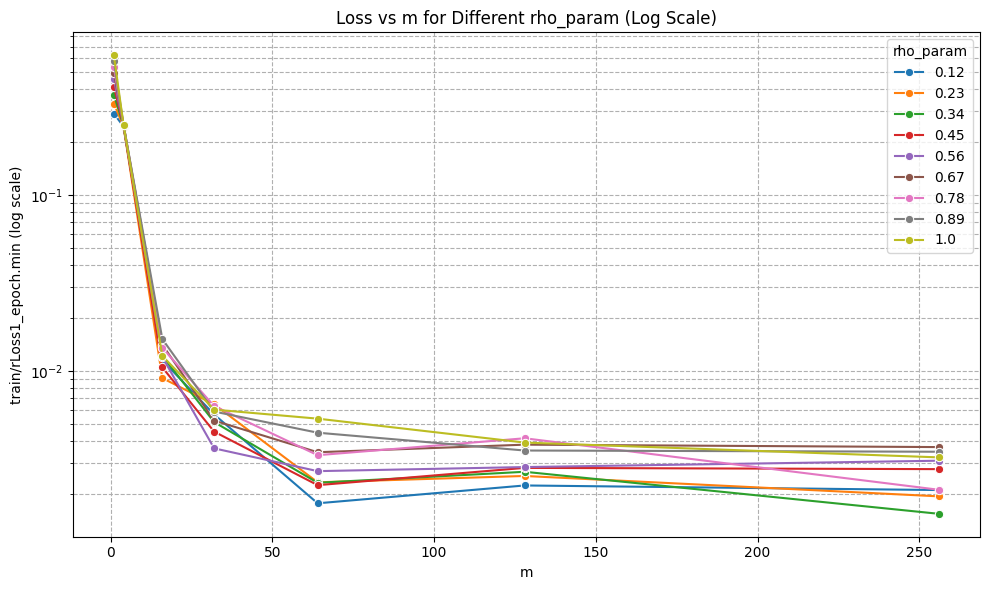

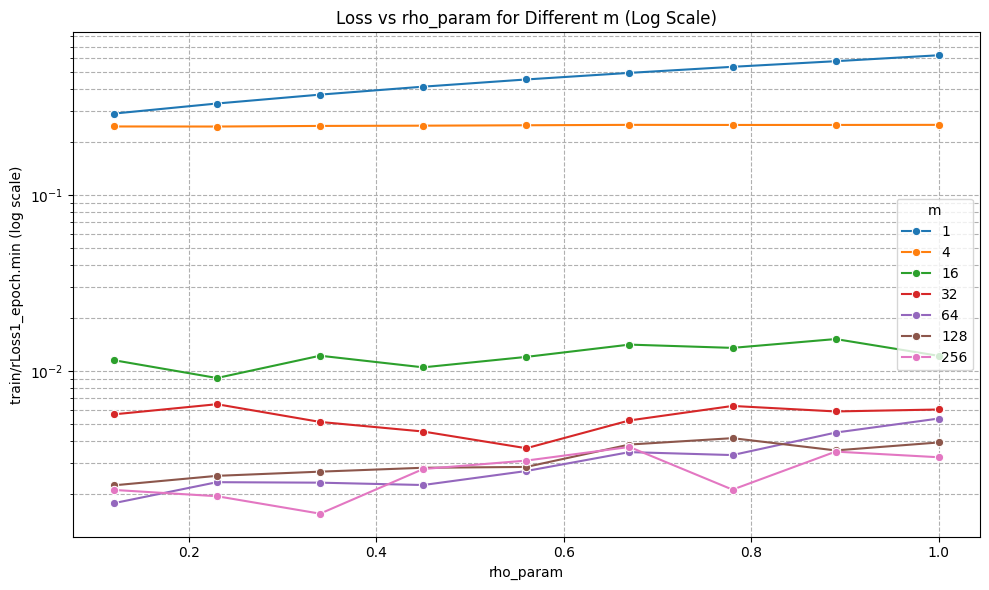

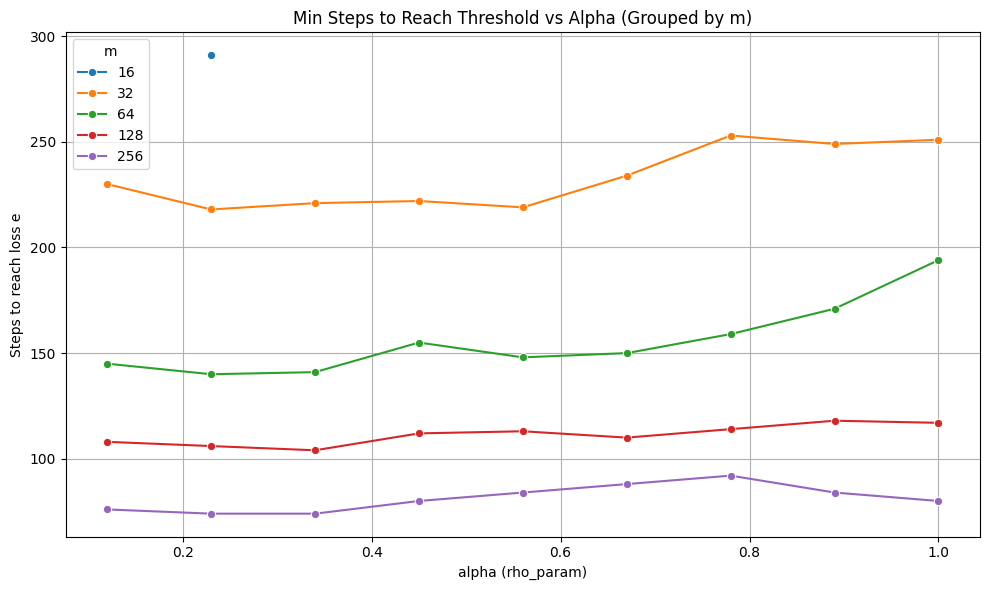

In [63]:
plot_basic('Transformer_impulse_step1', 'Trans_hid_dim', legend1=True, e=1e-2, conditions=["`module.layers.Layer1.nhead`==1", "m>0","`data.rho_param.alpha`>=0.1"])

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


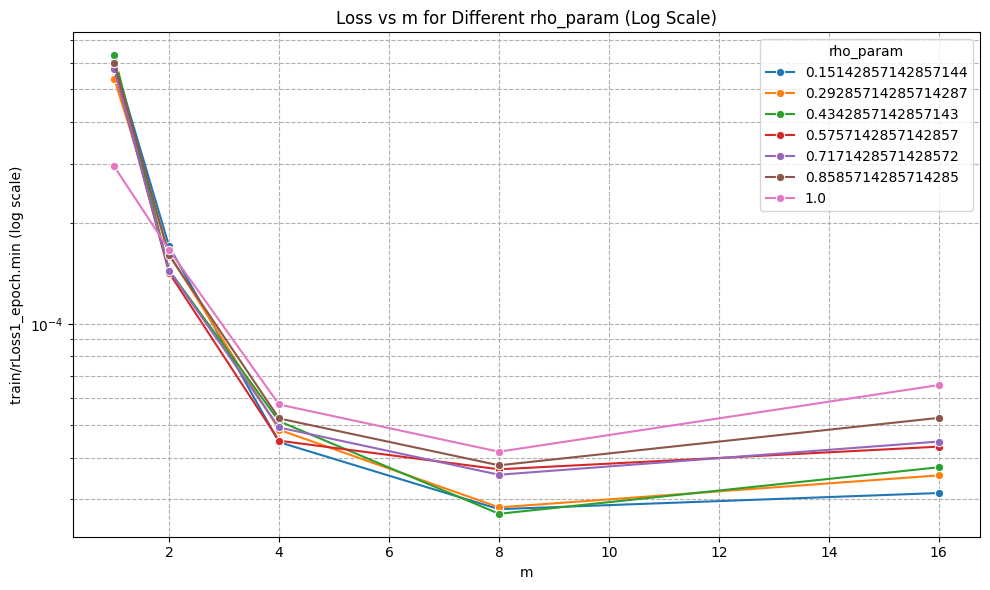

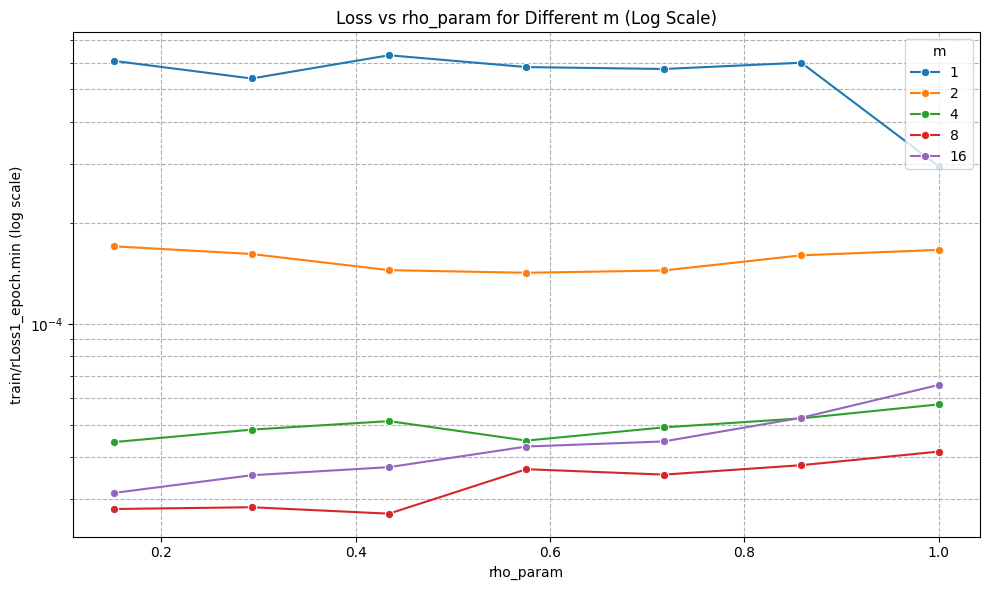

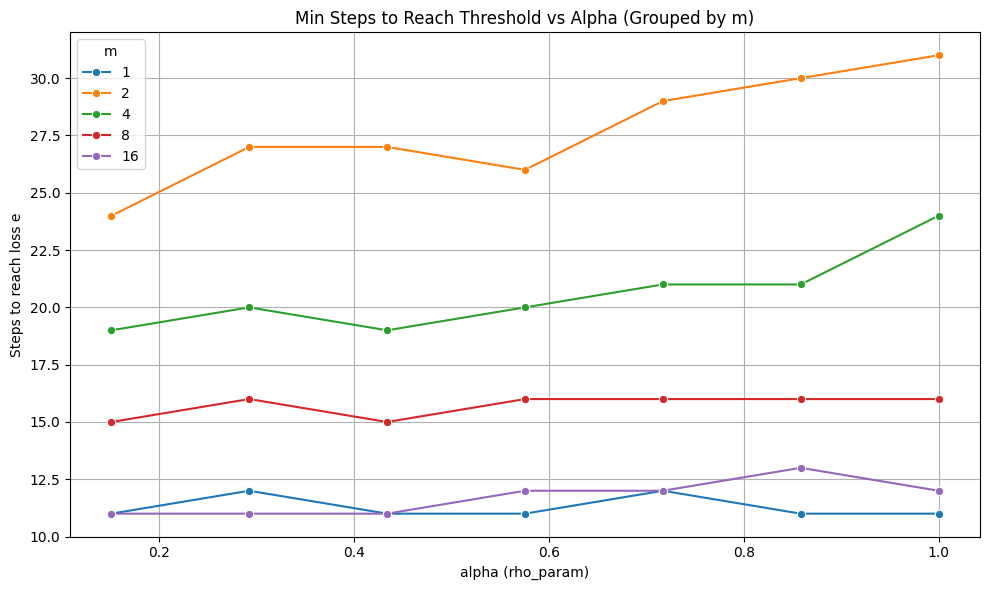

In [66]:
plot_basic('Transformer_impulse_step3', 'Trans_nhead', legend1=True, e=1e-2, conditions=[ "m>0","`data.rho_param.alpha`>=0.1"])

## Transformer Airy

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


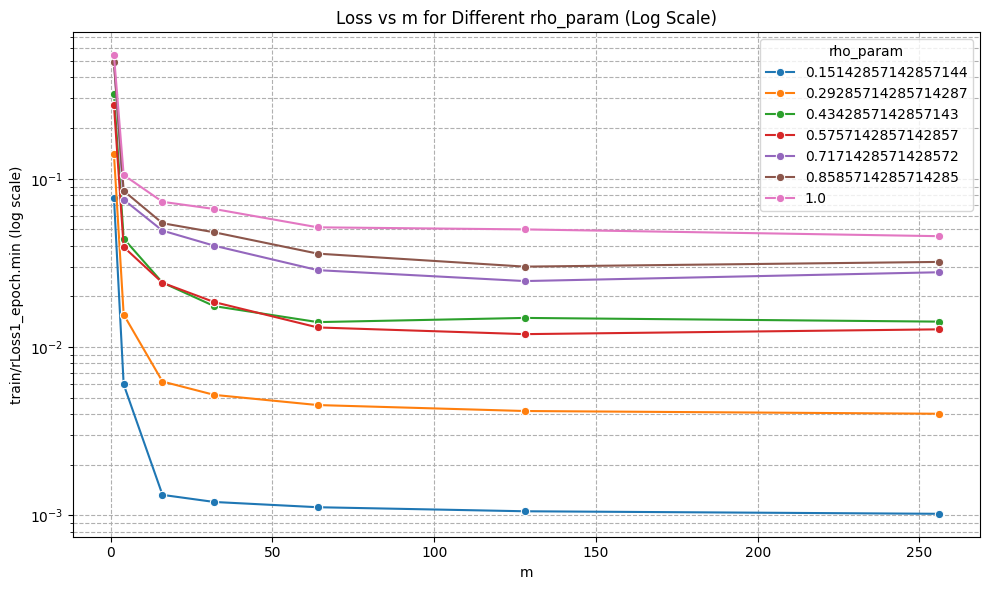

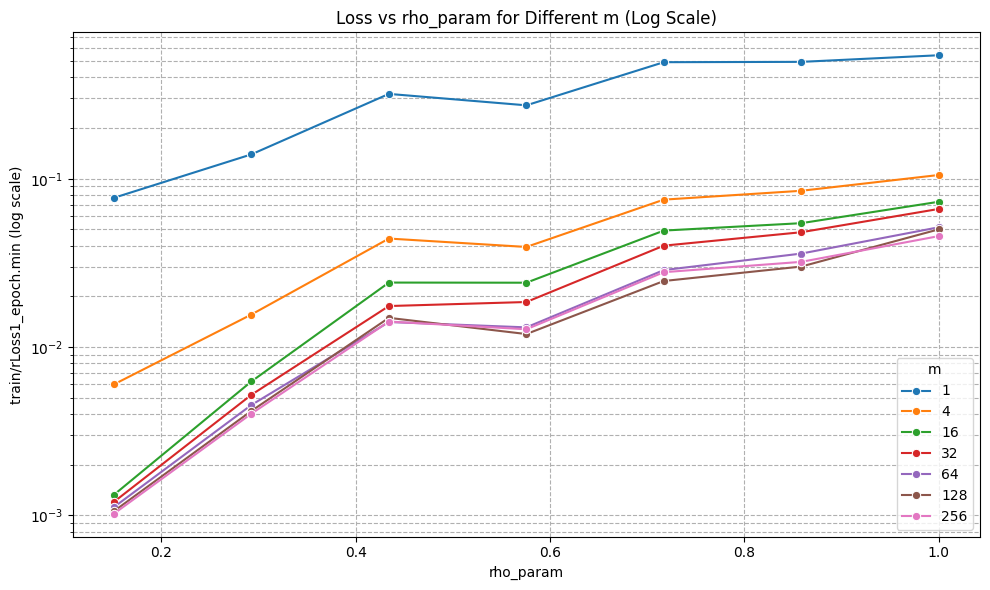

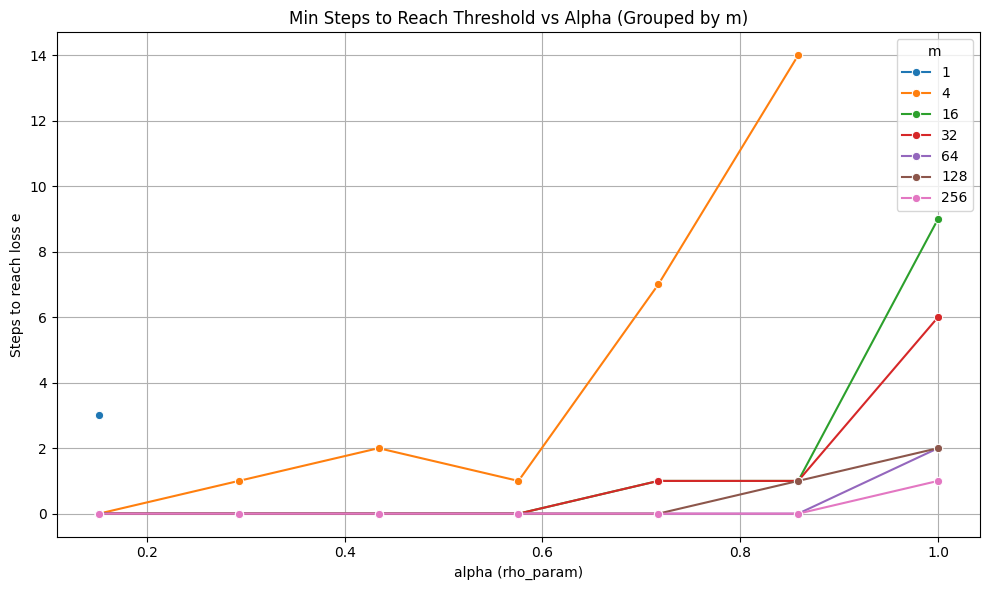

In [71]:
plot_basic('Transformer_airy_step3', 'Trans_hid_dim', legend1=True, e=1e-1, conditions=["`module.layers.Layer1.nhead`==1", "m>0","`data.rho_param.alpha`>=0.1"])

/tmp/ipykernel_3920779/930911437.py:14: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df['steps_to_reach_e'] = df['loss_history'].apply(


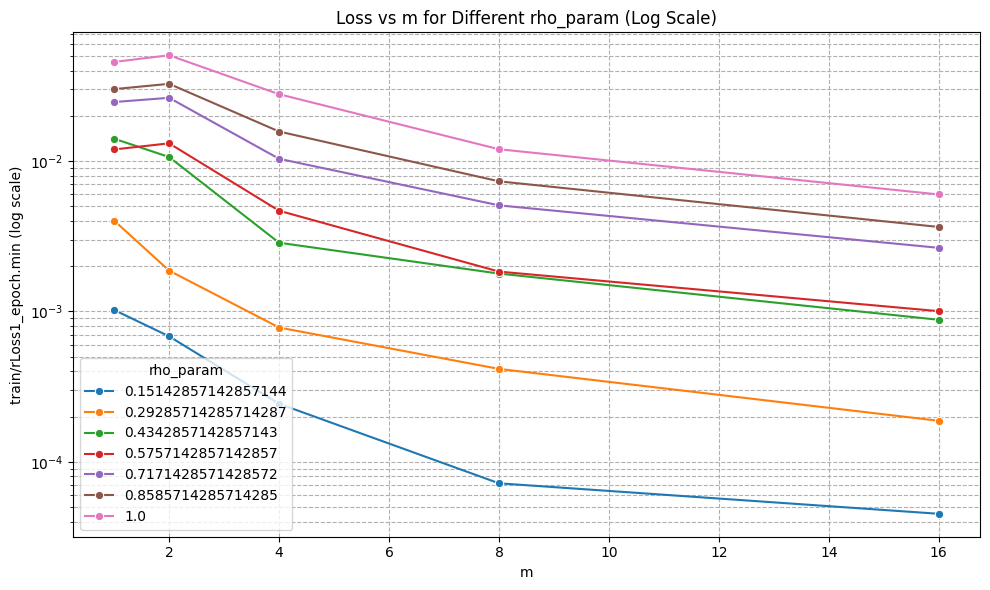

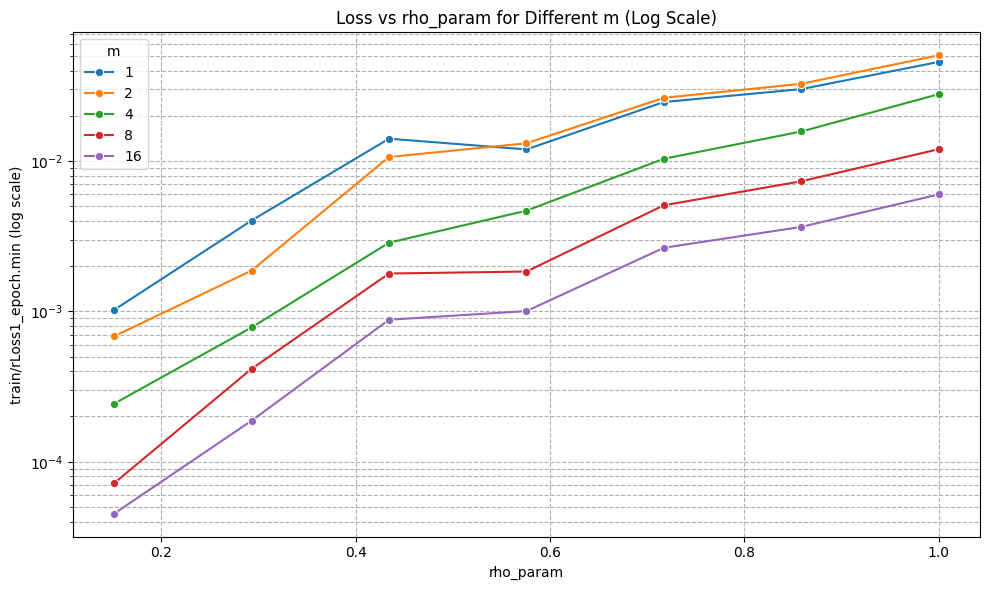

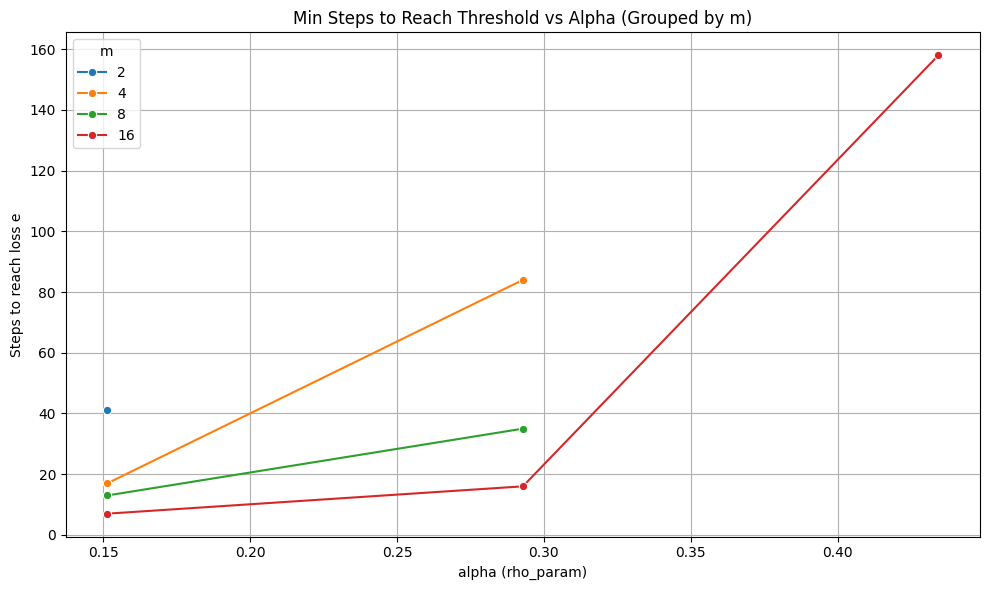

In [72]:
plot_basic('Transformer_airy_step3', 'Trans_nhead', legend1=True, e=1e-3, conditions=[ "m>0","`data.rho_param.alpha`>=0.1"])

In [73]:
# def make_normalizer(min_val, max_val, T_poly, T_exp):
#     import math
#     f_poly = lambda alpha: (alpha - min_val) / (max_val - min_val)
#     f_exp = lambda alpha1: f_poly(alpha1/T_exp * math.log(1+T_poly))
#     return f_exp, f_poly

In [50]:
def exp_vs_poly(project, m_key, mapper=None, conditions=None, path='./notebooks/Dataset/step1/data2'):

    df = pd.read_pickle(f"{path}/{project}_data_clean.pkl")
    df['m'] = df[m_key]


    if mapper is not None:
        df_t = pd.read_pickle(f"{path}/{mapper}_data_clean.pkl")
        a1 = np.sort(df['data.rho_param.alpha'].unique())
        a2 = np.sort(df_t['data.rho_param.alpha'].unique())

        alpha_mapping = dict(zip(a1, a2))

        df['data.rho_param.alpha'] = df['data.rho_param.alpha'].map(alpha_mapping)


    df['m'] = df[m_key]

    if conditions:
        for op in conditions:
            df = df.query(op)

    plt.figure(figsize=(10, 6))
    
    df_min = df.groupby(['m', 'data.rho_param.alpha'], as_index=False)['train/rLoss1_epoch.min'].min()

    return df_min

In [51]:
def plot_together(df1, df2):

    # Create the lineplot with x as rho_param, y as loss, each line for a different m
    plt.figure(figsize=(10, 6))
    palette1 = sns.color_palette("tab10", n_colors=len(df1['m'].unique()))
    palette2 = sns.color_palette("Set2", n_colors=len(df2['m'].unique()))


    df1['label'] = df1['m'].apply(lambda m: f"exp - m={m}")
    df2['label'] = df2['m'].apply(lambda m: f"poly - m={m}")        


    ax = sns.lineplot(
        data=df1,
        x='data.rho_param.alpha',
        y='train/rLoss1_epoch.min',
        hue='label',
        marker='o',
        palette=palette1
    )
    for line in ax.lines:
        line.set_markersize(8) 
    
    ax = sns.lineplot(
        data=df2,
        x='data.rho_param.alpha',
        y='train/rLoss1_epoch.min',
        hue='label',
        marker='s',
        palette=palette2
    )

    for line in ax.lines:
        line.set_markersize(8) 


    plt.yscale('log')
    plt.title('Loss vs rho_param for Different m (Log Scale)')
    plt.xlabel('rho_param')
    plt.ylabel('train/rLoss1_epoch.min (log scale)')
    plt.legend(title='m1')
    plt.grid(True, which="both", ls="--")
    plt.tight_layout()
    # plt.show()


<Figure size 1000x600 with 0 Axes>

<Figure size 1000x600 with 0 Axes>

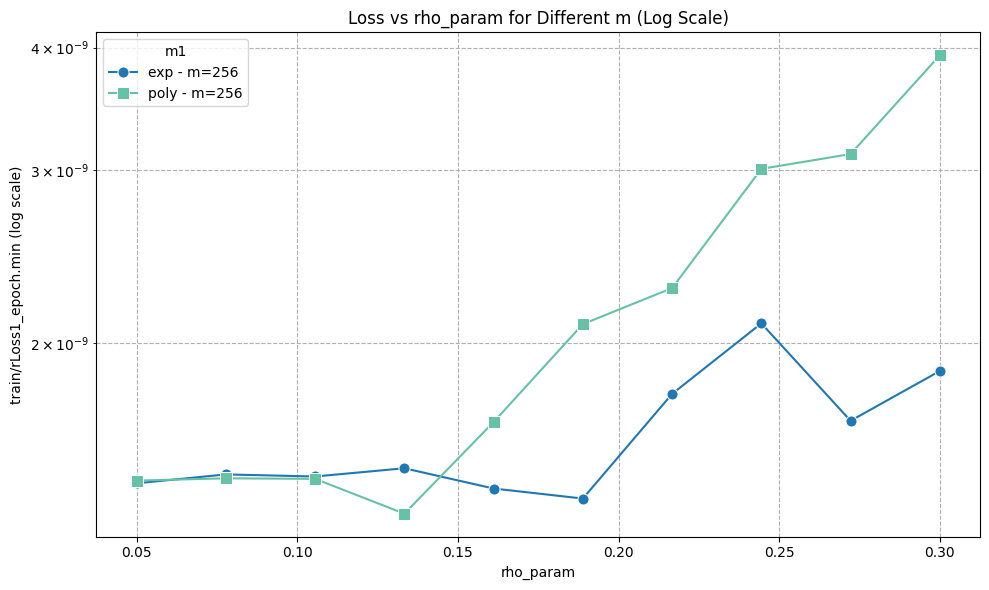

In [52]:
project_exp = 'LSTM_exp_step3'
project_poly = 'LSTM_poly_step3'

df_exp = exp_vs_poly(project_exp,  'module.layers.LSTM.hidden_size', mapper=project_poly, conditions=[('m>128')])
df_poly = exp_vs_poly(project_poly,  'module.layers.LSTM.hidden_size', conditions=[('m>128')])

plot_together(df_exp, df_poly)



In [55]:
def plot_loss(project, model, legend1=True, e=1e-6, conditions=None, alpha_list = None, path='./notebooks/Dataset/step1/data2'):

    m_key = m_key_dict[model]

    df = pd.read_pickle(f"{path}/{project}_data_clean.pkl")
    df['m'] = df[m_key]
    



    if conditions:
        for op in conditions:
            df = df.query(op)

    
    plt.figure(figsize=(10, 6))
    


    df = df[df['m'] == df['m'].max()]

    closest_rows = []
    if alpha_list:
        for target in alpha_list:
            # Compute absolute difference from the target
            idx_closest = (df['data.rho_param.alpha'] - target).abs().idxmin()
            closest_rows.append(df.loc[idx_closest])
        
        df = pd.DataFrame(closest_rows)


    df_long = pd.DataFrame([
        {"alpha": df['data.rho_param.alpha'][idx], "step": i, "loss": val}
        for idx, row in df['loss_history'].items()
        for i, val in enumerate(row)
    ])
    
    sns.lineplot(data=df_long, x="step", y="loss", hue="alpha", palette="tab10")


    plt.yscale('log')
    plt.title('Loss vs rho_param for Different m (Log Scale)')
    plt.xlabel('rho_param')
    plt.ylabel('train/rLoss1_epoch.min (log scale)')
    plt.legend(title='m')
    plt.grid(True, which="both", ls="--")
    plt.tight_layout()
    plt.show()

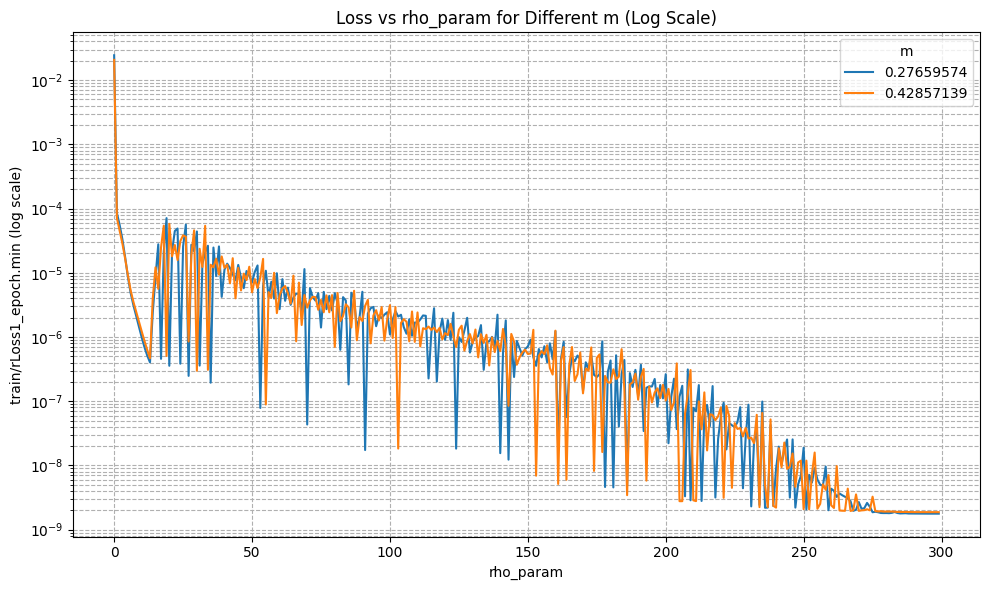

In [57]:
plot_loss('LSTM_exp_step3', 'LSTM', alpha_list=[0.3, 0.5])

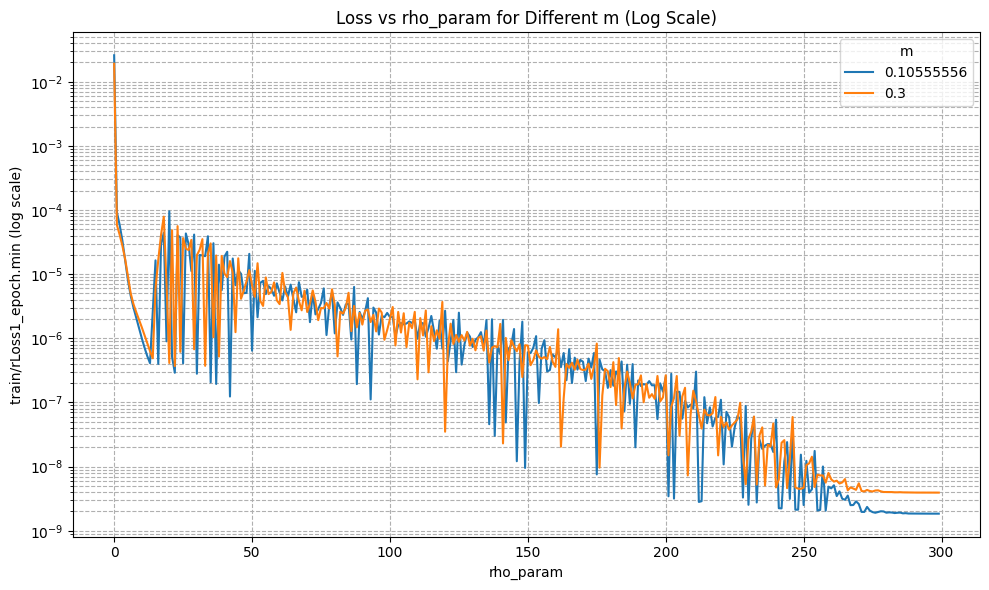

In [58]:
plot_loss('LSTM_poly_step3', 'LSTM', alpha_list=[0.1, 0.3])

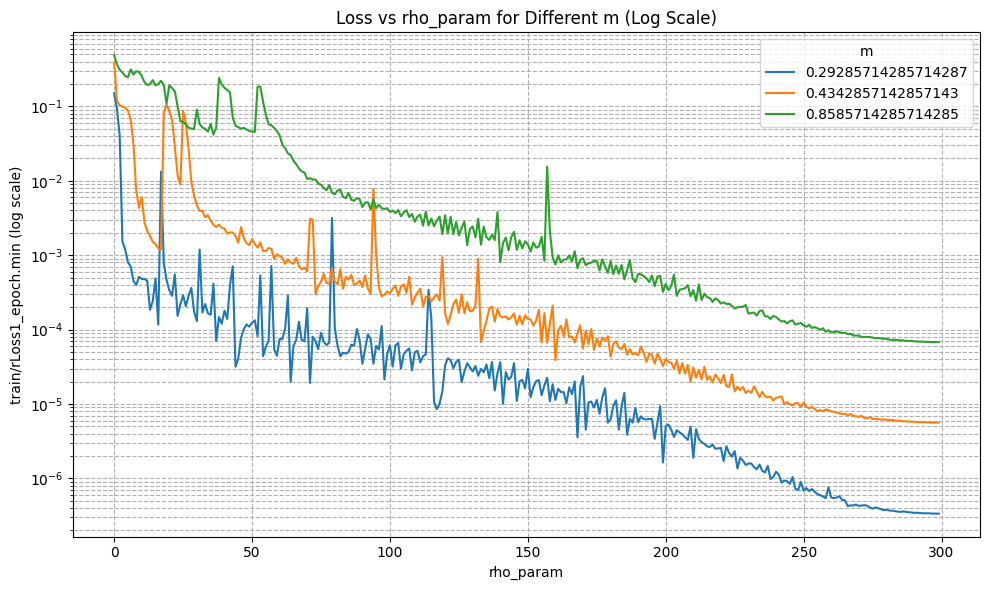

In [59]:
plot_loss('LSTM_airy_step3', 'LSTM', alpha_list=[0.3, 0.4, 0.8])

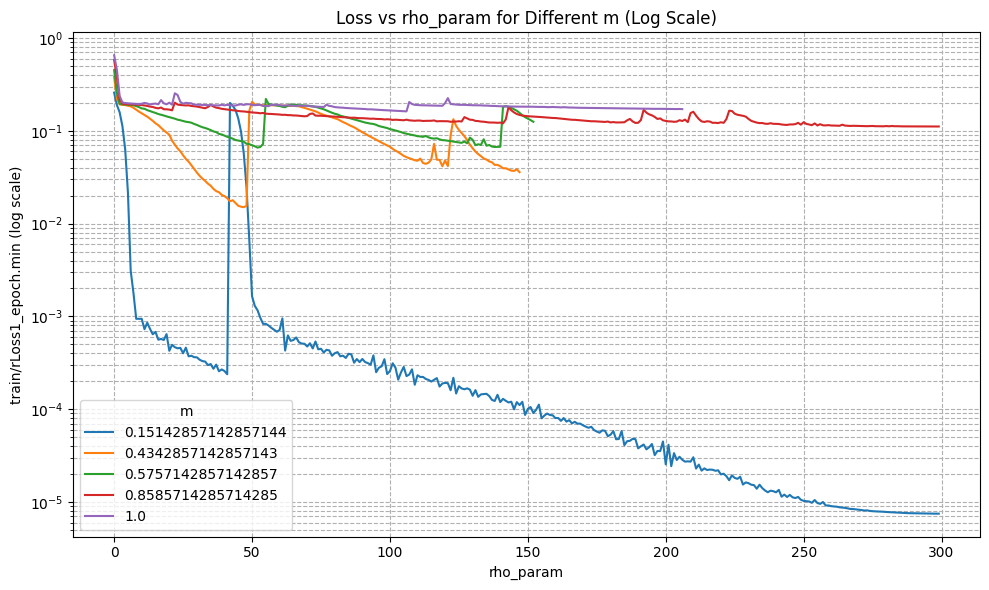

In [60]:
plot_loss('LSTM_impulse_step3', 'LSTM', alpha_list=[0.2,0.4,0.6,0.8,1])

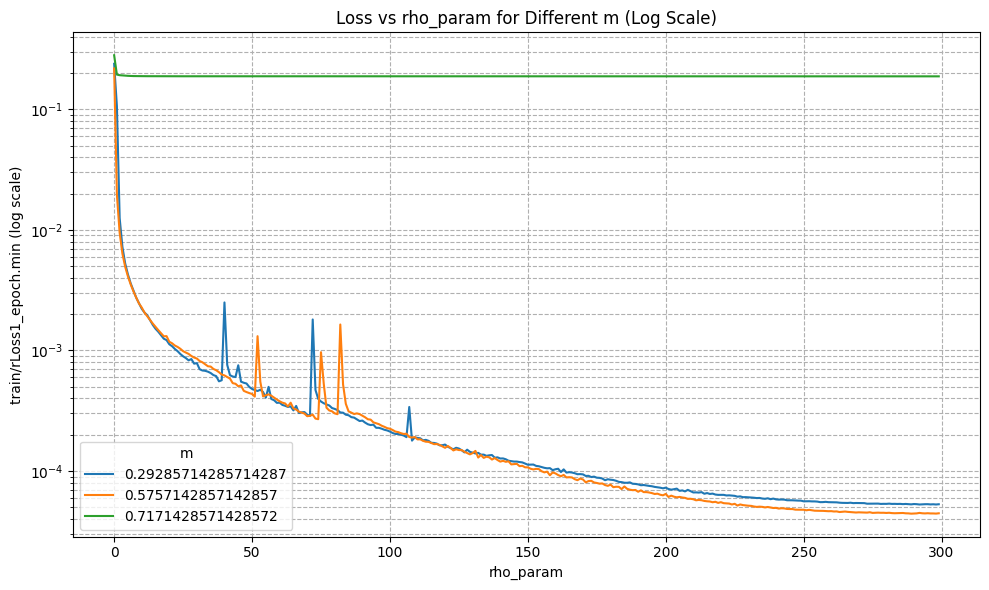

In [61]:
plot_loss('TCN_impulse_step3', 'TCN', alpha_list=[0.3,0.6, 0.7])

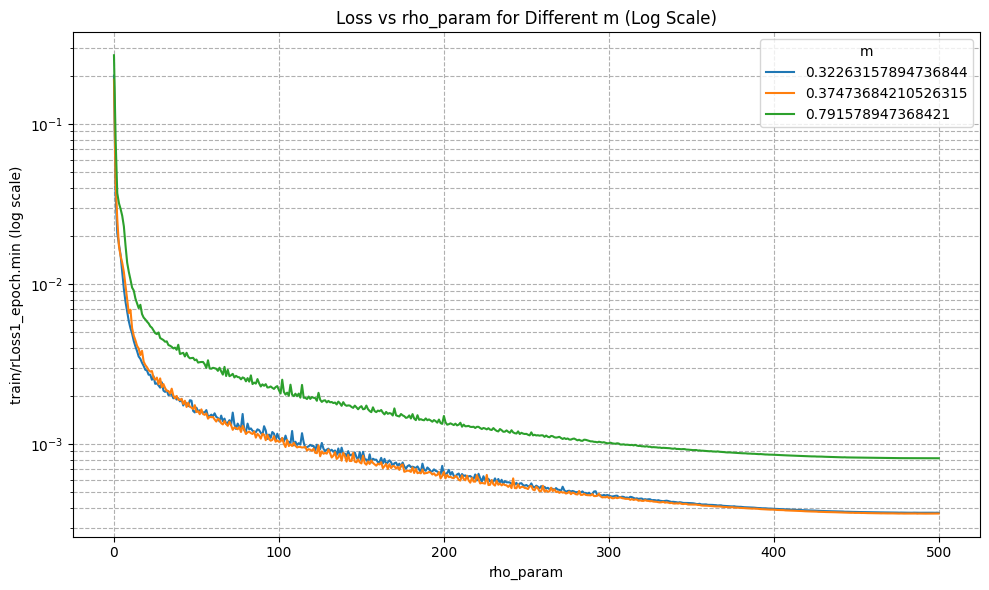

In [62]:
plot_loss('TCN_airy_step1', 'TCN', alpha_list=[0.3, 0.4, 0.8])

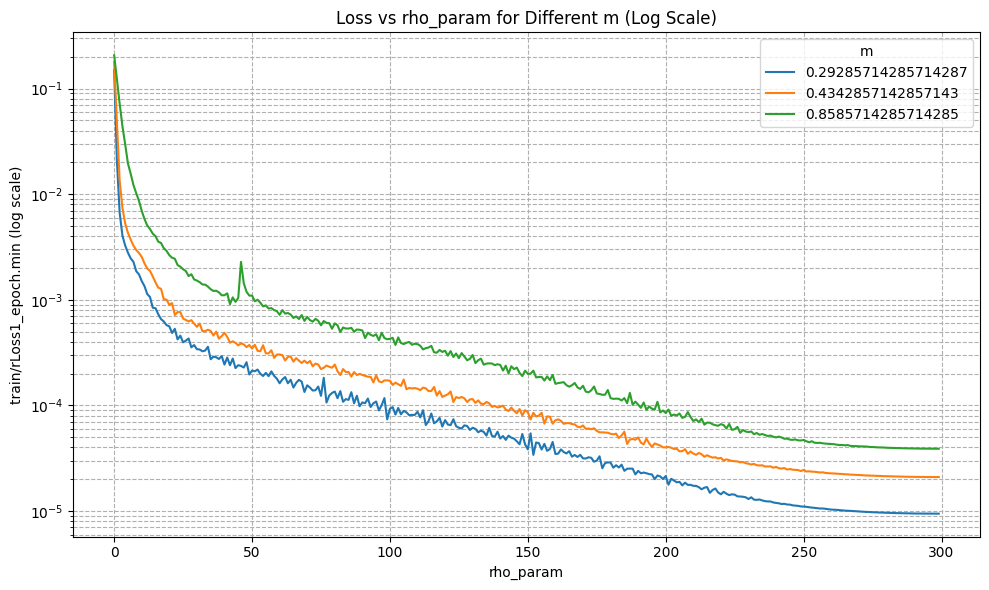

In [63]:
plot_loss('S4_impulse_step3', 'S4', alpha_list=[0.3, 0.4, 0.8])

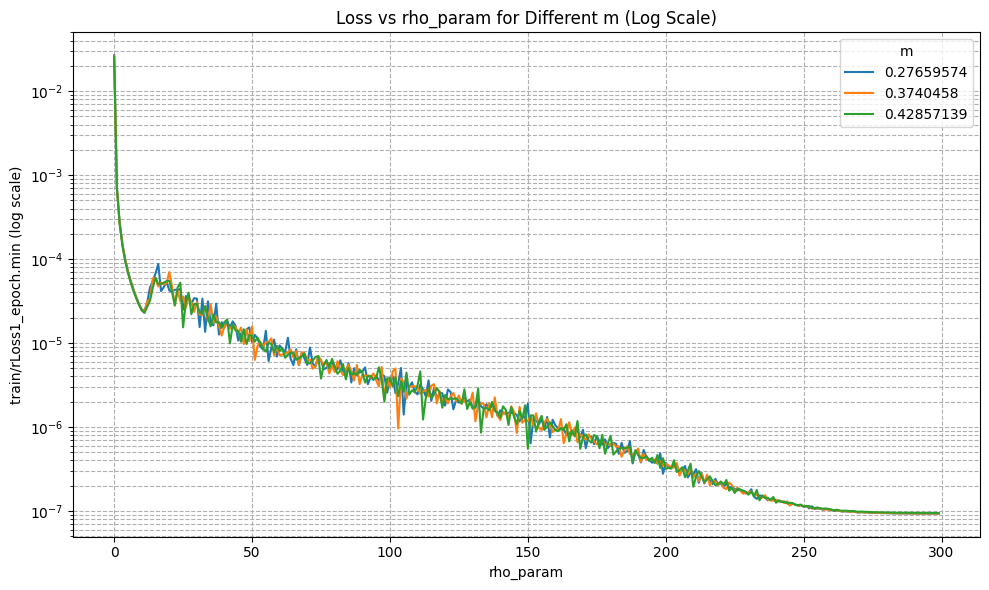

In [64]:
plot_loss('S4_exp_step3', 'S4', alpha_list=[0.3, 0.4, 0.8])

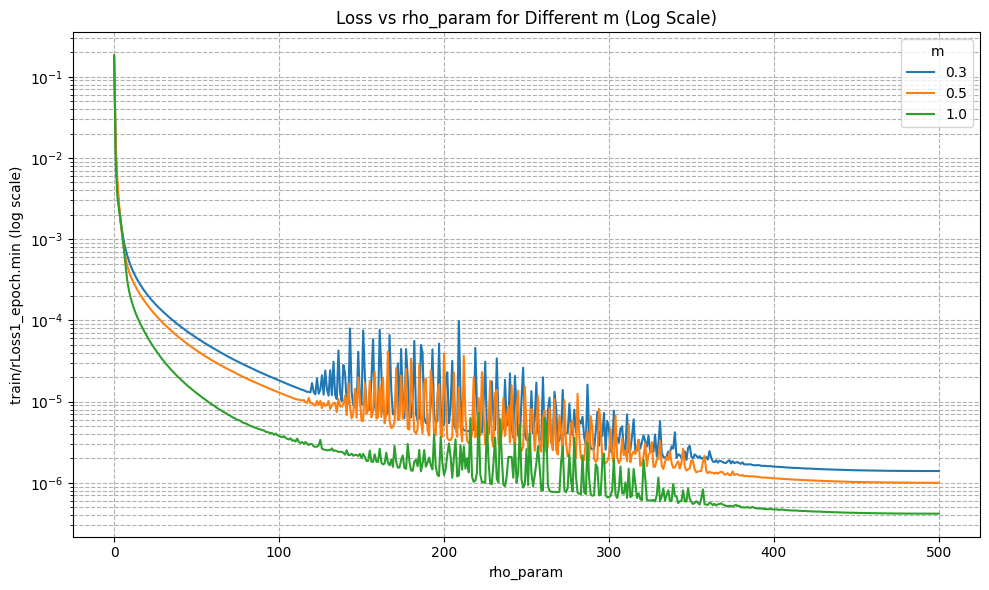

In [68]:
plot_loss('S4_poly_step1', 'S4', alpha_list=[0.3, 0.4, 0.8])

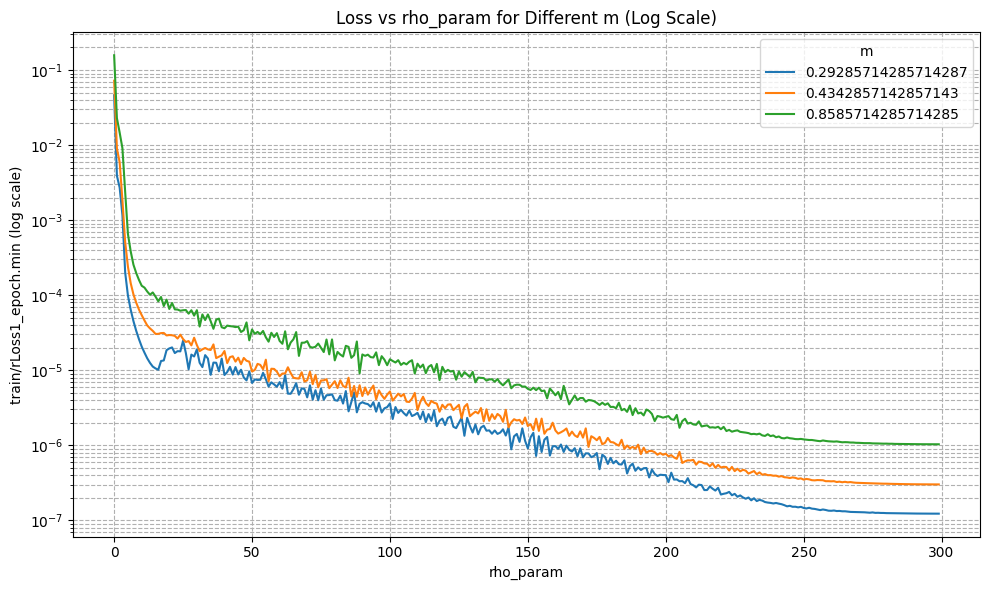

In [66]:
plot_loss('S4_airy_step3', 'S4', alpha_list=[0.3, 0.4, 0.8])